<a id="top"></a>


# Лабораторная работа №1 · Прикладная статистика

**Команда:** ic22

**Члены команды:**
- **Инфохимия** (разделы [1](#s1) и [2](#s2)): Мамедгасанов Гашам, Дрожжина Анна, Михайлова Мария
- **Дизайн, КТвД** (раздел [3](#ktvd) и оформление документа): Караева Станислава, Котикова Елизавета

**Цель работы:** освоить полный цикл статистического анализа и стохастического моделирования реальных физико-химических данных на примере датасета ESOL (Delaney, 2004) о водной растворимости органических соединений. В блоке КТвД тот же подход применён ко второму датасету (Wine Quality), а генератор случайных чисел сделан интерактивным.

> **Как запустить.** Ячейки зависят друг от друга, поэтому запускайте ноутбук целиком: в Colab – «Среда выполнения → Выполнить все» (Ctrl+F9), в Jupyter – «Run → Run All Cells». Если запустить одну ячейку из середины, она подскажет, что нужно выполнить ячейки выше.
>
> Код во всех ячейках скрыт. В Jupyter он раскрывается кликом по «…» слева от ячейки, в Colab – двойным кликом по заголовку формы. Все графики и таблицы строятся кодом при запуске.

<a id="tasks"></a>


### Задачи по спринтам

**Спринт 1 – статистический анализ**

1. **Описать данные.** Провести разведочный анализ (EDA) трёх случайных величин – `LogS` (растворимость), `MW` (молекулярная масса), `TPSA` (полярная площадь поверхности) – и всего датасета целиком.
2. **Обосновать стохастичность.** Показать, что каждая величина является случайной, а не детерминированной: привести физико-химические и экспериментальные причины вариабельности.
3. **Подобрать распределения.** Сопоставить эмпирические распределения с теоретическими законами (нормальный, логнормальный, экспоненциальный, гамма) и проверить согласие статистическими тестами.
4. **Проверить гипотезы.** Сформулировать и проверить статистические гипотезы о нормальности, о различии групп (лёгкие/тяжёлые молекулы, полярные/неполярные) и о согласии с теоретическим законом.
5. **Оценить зависимости.** Проверить корреляции между величинами (Пирсон и Спирмен) и воспроизвести ключевой вывод оригинальной статьи Delaney (2004): молекулярная масса – главный предиктор растворимости.
6. **Исследовать оценки.** Эмпирически показать состоятельность выборочных оценок среднего и дисперсии, сравнить выборки с возвращением и без.

**Спринт 2 – генерация случайных чисел**

1. **Разработать собственный ГСЧ.** Реализовать генератор случайных чисел для `LogS` без использования встроенных функций целевых распределений, опираясь только на базовый равномерный датчик «Вихрь Мерсенна».
2. **Освоить два алгоритма.** Реализовать метод полярных координат Марсальи (для нормального закона) и метод обратной функции (для логистического закона).
3. **Проверить генератор.** Написать автотесты и сравнить статистики синтетических выборок с реальными данными.
4. **Обосновать выбор.** Провести аналитический обзор 8 алгоритмов датчиков случайных чисел с опорой на академическую литературу.

**Блок КТвД – оформление и доп. задание**

1. **Оформить документ.** Пронумеровать разделы, добавить оглавление и якорные ссылки, скрыть код, привести графики к единому стилю с корректными масштабами и единицами, записать формулы в LaTeX единообразно.
2. **Исследовать второй датасет.** Взять Wine Quality и две величины одной природы – pH и фиксированную кислотность: доказать, что это случайные величины, проверить их зависимость, провести EDA.
3. **Сделать генератор интерактивным.** Добавить управление параметрами генератора прямо в ноутбуке (ipywidgets) и отдельное приложение на marimo.

<a id="toc"></a>


### Оглавление

| № | Раздел | Что внутри |
|---|---|---|
| **0** | [**О работе**](#top) | команда, цель, [задачи по спринтам](#tasks), [обозначения](#notation) |
| **1** | [**Lab01 - sprint 1**](#s1) | три случайные величины датасета ESOL |
| 1.1 | [Random Variable 01 – LogS](#rv01) | растворимость: природа, EDA, состоятельность, выборки, гипотезы |
| 1.2 | [Random Variable 02 – MW](#rv02) | молекулярная масса |
| 1.3 | [Random Variable 03 – TPSA](#rv03) | полярная площадь поверхности |
| 1.4 | [Lab resume](#s1-resume) | выводы спринта 1, `cat_mark_table` |
| **2** | [**Lab01 - sprint 2**](#s2) | генератор случайных чисел для LogS |
| 2.1 | [random 01](#gen01) | описание, мат. обоснование, [обзор 8 датчиков](#gen01-algos), [литература](#gen01-lit), код, тесты |
| 2.2 | [Lab resume](#s2-resume) | выводы, `cat_mark_table` |
| **3** | [**Блок КТвД**](#ktvd) | доп. задание КТвД |
| 3.0 | [Задачи КТвД](#ktvd-0) | чек-лист, правки при объединении |
| 3.1 | [Датасет Wine Quality](#ktvd-1) | источник, единицы, качество данных |
| 3.2 | [Random Variable K1 – pH](#ktvd-2) | случайность, EDA, распределение |
| 3.3 | [Random Variable K2 – фикс. кислотность](#ktvd-3) | случайность, EDA, нормализация |
| 3.4 | [Зависимость pH и кислотности](#ktvd-4) | 4 критерия, химическая интерпретация |
| 3.5 | [Интерактивный генератор](#ktvd-5) | 3 метода × 3 величины, ipywidgets, marimo |
| 3.6 | [Lab resume КТвД](#ktvd-6) | выводы, `cat_mark_table`, литература |

<a id="notation"></a>


### Обозначения и оформление

| Символ | Смысл | Символ | Смысл |
|---|---|---|---|
| $X$ | случайная величина | $x_1,\dots,x_n$ | наблюдения, $n$ – объём выборки, $N$ – объём совокупности |
| $\mu,\ \sigma^2$ | математическое ожидание и дисперсия | $\bar{x},\ s^2$ | их выборочные оценки (дисперсия с поправкой $n-1$) |
| $Q_1,\ Q_3$ | нижний и верхний квартили | $\mathrm{IQR} = Q_3 - Q_1$ | межквартильный размах |
| $\gamma_1$ | коэффициент асимметрии | $\gamma_2$ | эксцесс (у нормального закона $\gamma_2 = 0$) |
| $r$ | корреляция Пирсона | $\rho_S,\ \tau$ | ранговые корреляции Спирмена и Кендалла |
| $H_0,\ H_1$ | нулевая и альтернативная гипотезы | $\alpha = 0.05$ | уровень значимости во всех тестах |
| $F(x),\ \hat{F}_n(x)$ | функция распределения и её эмпирическая оценка | $\mathrm{AIC} = 2k - 2\ln L$ | критерий Акаике, $k$ – число параметров |
| $U \sim \mathcal{U}(0,1)$ | базовое равномерное случайное число | $\mathcal{N}(\mu, \sigma^2)$ | нормальный закон |

**Цвета на графиках.** У каждой величины свой цвет во всём документе: 🟦 LogS · 🟩 MW · 🟪 TPSA · 🟥 pH · 🟧 фикс. кислотность. Теоретические кривые и выборки генератора – графитовые линии ⬛ (сплошная – лучшая модель или полярный метод, пунктир – вторая модель или метод обратной функции, точки – квантильное преобразование).


[↑ к оглавлению](#toc)

In [1]:
#@title Установка зависимостей (раскомментируйте строку при первом запуске)
# %pip install pandas numpy matplotlib scipy ipywidgets

In [2]:
#@title Настройка: библиотеки, единый стиль графиков, вспомогательные функции
import io
import warnings

import numpy as np
import pandas as pd
import matplotlib as mpl
import matplotlib.pyplot as plt
from matplotlib.ticker import FixedLocator, FuncFormatter, NullLocator
from scipy import stats
from IPython.display import display, Markdown

warnings.filterwarnings("ignore")
RNG_SEED = 42
ALPHA = 0.05

# ── Единая палитра: у каждой величины свой цвет (слоты проверенной палитры), текст и теория – графит ──
STYLE = {
    "surface": "#fcfcfb", "ink": "#0b0b0b", "ink2": "#52514e", "grid": "#e6e5e0", "neutral": "#c3c2b7",
    "seq": ["#fcfcfb", "#cde2fb", "#9ec5f4", "#6da7ec", "#3987e5", "#256abf", "#184f95", "#0d366b"],
}
VARS = {
    "LogS": dict(label="LogS", axis="LogS = lg S  (S в моль/л; безразмерная)", unit="безразмерная", color="#2a78d6", step=None),
    "MW": dict(label="MW", axis="MW, г/моль", unit="г/моль", color="#1baf7a", step=None),
    "TPSA": dict(label="TPSA", axis="TPSA, Å²", unit="Å²", color="#6250d6", step=None),
    "pH": dict(label="pH", axis="pH (безразмерная)", unit="безразмерная", color="#e34948", step=0.01),
    "fixed acidity": dict(label="Фикс. кислотность", axis="Фикс. кислотность, г/дм³", unit="г/дм³", color="#eb6834", step=0.1),
}
METHOD_NAME = {"polar": "Полярный метод Марсальи", "inverse": "Обратная функция (логистич.)",
               "quantile": "Квантильное преобразование"}
METHOD_SHORT = {"polar": "полярный метод", "inverse": "обратная функция", "quantile": "квантильный метод"}
METHOD_LS = {"polar": "-", "inverse": "--", "quantile": ":"}

mpl.rcParams.update({
    "figure.facecolor": STYLE["surface"], "axes.facecolor": STYLE["surface"],
    "savefig.facecolor": STYLE["surface"], "figure.dpi": 110,
    "font.family": "DejaVu Sans", "font.size": 10,
    "axes.titlesize": 11.5, "axes.titleweight": "bold", "axes.titlelocation": "left", "axes.titlepad": 10,
    "axes.labelsize": 10, "axes.labelcolor": STYLE["ink2"], "axes.edgecolor": STYLE["grid"],
    "axes.spines.top": False, "axes.spines.right": False,
    "axes.grid": True, "grid.color": STYLE["grid"], "grid.linewidth": 0.8, "grid.linestyle": "-",
    "axes.axisbelow": True,
    "xtick.color": STYLE["ink2"], "ytick.color": STYLE["ink2"], "xtick.labelsize": 9, "ytick.labelsize": 9,
    "legend.frameon": False, "legend.fontsize": 9, "lines.linewidth": 2,
})

_COUNT = {"table": 0, "figure": 0}


def show(df, caption=None, fmt="{:.4g}", highlight_row=None):
    """Таблица с автонумерацией, без индекса; при желании подсвечивается строка."""
    _COUNT["table"] += 1
    cap = f"Таблица {_COUNT['table']}. {caption}" if caption else None
    try:
        sty = df.style.hide(axis="index").format(fmt, subset=df.select_dtypes("number").columns, na_rep="–")
        if cap:
            sty = sty.set_caption(cap)
        sty = sty.set_table_styles([
            {"selector": "caption", "props": "caption-side: top; text-align: left; font-weight: 600; color: #0b0b0b; padding-bottom: 6px;"},
            {"selector": "th", "props": "text-align: left; color: #52514e; font-weight: 600; border-bottom: 1px solid #c3c2b7;"},
            {"selector": "td", "props": "text-align: left; padding: 3px 10px;"},
        ])
        sty = sty.set_properties(subset=df.select_dtypes("number").columns, **{"white-space": "nowrap"})
        if highlight_row is not None:
            sty = sty.apply(lambda r: ["background-color: #cde2fb" if r.name == highlight_row else "" for _ in r], axis=1)
        display(sty)
    except Exception:
        print(cap or "")
        display(df)


def fig_caption(text):
    """Подпись к рисунку с автонумерацией."""
    _COUNT["figure"] += 1
    display(Markdown(f"<small>**Рис. {_COUNT['figure']}.** {text}</small>"))


def read_csv_any(sources, **kw):
    """Читает CSV из первого доступного источника (на macOS + Python 3.14 – обход ошибки сертификатов)."""
    for src in sources:
        try:
            return pd.read_csv(src, **kw), src
        except Exception:
            try:
                import requests, urllib3
                urllib3.disable_warnings(urllib3.exceptions.InsecureRequestWarning)
                r = requests.get(src, verify=False, timeout=20)
                r.raise_for_status()
                return pd.read_csv(io.StringIO(r.text), **kw), src
            except Exception:
                continue
    raise RuntimeError(f"Не удалось загрузить данные: положите файл {sources[-1]} рядом с ноутбуком")


def step_bins(x, step=None):
    """Бины, кратные шагу записи прибора (иначе дискретные значения дают «зубчатую» гистограмму)."""
    x = np.asarray(x)
    edges = np.histogram_bin_edges(x, bins="fd")
    if not step:
        return edges
    width = step * max(1, round((edges[1] - edges[0]) / step))
    start = np.floor(x.min() / step + 1e-9) * step - step / 2   # границы – посередине между значениями сетки прибора
    return np.arange(start, x.max() + width, width)


def describe_rv(x, key):
    """Сводная таблица описательных статистик (единый набор для всех величин)."""
    s = pd.Series(x)
    u = VARS[key]["unit"]
    u2 = "–" if u == "безразмерная" else f"({u})²"
    q1, q3 = s.quantile([0.25, 0.75])
    iqr = q3 - q1
    rows = [
        ("Объём выборки n", s.count(), "шт."),
        ("Пропущенные значения", int(s.isna().sum()), "шт."),
        ("Среднее x̄", s.mean(), u), ("Медиана", s.median(), u), ("Мода", s.mode().iloc[0], u),
        ("Дисперсия s²", s.var(), u2), ("СКО s", s.std(), u),
        ("Коэф. вариации s / |x̄|", s.std() / abs(s.mean()), "–"),
        ("Минимум", s.min(), u), ("Квартиль Q₁", q1, u), ("Квартиль Q₃", q3, u), ("Максимум", s.max(), u),
        ("IQR = Q₃ − Q₁", iqr, u),
        ("Выбросы по правилу 1.5·IQR", int(((s < q1 - 1.5 * iqr) | (s > q3 + 1.5 * iqr)).sum()), "шт."),
        ("Асимметрия γ₁", s.skew(), "–"), ("Эксцесс γ₂", s.kurtosis(), "–"),
    ]
    return pd.DataFrame(rows, columns=["Статистика", "Значение", "Ед. изм."])


CANDIDATES = {"Нормальное": stats.norm, "Логистическое": stats.logistic, "Логнормальное": stats.lognorm,
              "Гамма": stats.gamma, "Экспоненциальное": stats.expon}


def fit_candidates(x, names=("Нормальное", "Логистическое", "Логнормальное", "Гамма"), floc=None):
    """Подгонка моделей методом максимального правдоподобия: AIC и критерий Колмогорова–Смирнова."""
    rows = []
    for name in names:
        dist = CANDIDATES[name]
        params = dist.fit(x) if floc is None or name in ("Нормальное", "Логистическое") else dist.fit(x, floc=floc)
        k = len(params) - (floc is not None and name not in ("Нормальное", "Логистическое"))
        loglik = dist.logpdf(x, *params).sum()
        ks = stats.kstest(x, dist(*params).cdf)
        rows.append({"Распределение": name, "Параметров k": k, "AIC": 2 * k - 2 * loglik,
                     "КС: D": ks.statistic, "КС: p-value": ks.pvalue,
                     "Вывод (α = 0.05)": "не отвергается" if ks.pvalue > ALPHA else "отвергается",
                     "_params": params, "_dist": dist})
    return pd.DataFrame(rows).sort_values("AIC").reset_index(drop=True)


def models_from_fits(fits, k=2, scale=1.0):
    return [dict(label=f"{r['Распределение']} (AIC {r['AIC']:.0f})",
                 pdf=lambda g, d=r["_dist"], p=r["_params"]: scale * d.pdf(g, *p)) for _, r in fits.head(k).iterrows()]


def hyp_table(rows, caption):
    """Гипотезы – таблицей: H₀, критерий, статистика, p-value и решение при α = 0.05."""
    df = pd.DataFrame(rows, columns=["Нулевая гипотеза H₀", "Критерий", "Статистика", "p-value"])
    df["Решение (α = 0.05)"] = np.where(df["p-value"] < ALPHA, "H₀ отвергается", "H₀ не отвергается")
    show(df, caption, fmt="{:.4g}")


def eda_figure(x, key, models=(), caption=None, annotate_zero=None):
    """Три панели в одном формате: гистограмма + модели, ящик с усами, Q-Q к нормальному закону."""
    x = np.asarray(x)
    c, axis = VARS[key]["color"], VARS[key]["axis"]
    fig, ax = plt.subplots(1, 3, figsize=(13, 3.9), gridspec_kw={"width_ratios": [1.35, 1, 1]})
    bins = step_bins(x, VARS[key]["step"])
    if annotate_zero is not None:
        bins = np.histogram_bin_edges(x, bins="fd", range=(0, x.max()))
    ax[0].hist(x, bins=bins, density=True, color=c, alpha=0.55, edgecolor=STYLE["surface"], linewidth=1)
    lo = 0 if annotate_zero is not None else x.min() - 0.05 * np.ptp(x)
    grid = np.linspace(lo, x.max() + 0.05 * np.ptp(x), 500)
    styles = [dict(color=STYLE["ink"], ls="-", lw=2), dict(color=STYLE["ink2"], ls="--", lw=1.5),
              dict(color=STYLE["ink2"], ls=":", lw=1.5)]
    for m, st in zip(models, styles):
        ax[0].plot(grid, m["pdf"](grid), color=st["color"], linestyle=st["ls"], linewidth=st["lw"], label=m["label"])
    if annotate_zero is not None:
        top = np.histogram(x, bins=bins, density=True)[0][0]
        ax[0].annotate(annotate_zero, xy=(bins[1] / 2, top), xytext=(0.35, 0.88), textcoords="axes fraction",
                       fontsize=9, color=STYLE["ink2"], arrowprops=dict(arrowstyle="->", color=STYLE["ink2"], lw=1))
        ax[0].set_ylim(0, top * 1.08)
    ax[0].set_title("Плотность: данные и модели")
    ax[0].set_xlabel(axis); ax[0].set_ylabel("Плотность вероятности")
    if models:
        ax[0].legend(loc="best" if annotate_zero is None else "center right")

    ax[1].boxplot(x, vert=False, widths=0.45, patch_artist=True,
                  boxprops=dict(facecolor=c, alpha=0.35, edgecolor=STYLE["ink2"]),
                  medianprops=dict(color=STYLE["ink"], linewidth=2),
                  whiskerprops=dict(color=STYLE["ink2"]), capprops=dict(color=STYLE["ink2"]),
                  flierprops=dict(marker="o", markersize=4, markerfacecolor=c, markeredgecolor=STYLE["surface"], alpha=0.8))
    ax[1].set_yticks([]); ax[1].grid(axis="y", visible=False)
    ax[1].set_title("Ящик с усами (усы = 1.5·IQR)"); ax[1].set_xlabel(axis)

    (osm, osr), (slope, intercept, _) = stats.probplot(x, dist="norm")
    ax[2].scatter(osm, osr, s=10, color=c, alpha=0.7, edgecolor="none")
    ax[2].plot(osm, slope * osm + intercept, color=STYLE["ink"], linewidth=1.5, label="нормальный закон")
    ax[2].set_title("Q-Q: данные против $\\mathcal{N}(\\bar{x}, s^2)$")
    ax[2].set_xlabel("Теоретические квантили $\\mathcal{N}(0, 1)$"); ax[2].set_ylabel(axis)
    ax[2].legend(loc="upper left")
    fig.tight_layout(); plt.show()
    if caption:
        fig_caption(caption)


def analyze_estimations_and_samples(series, key):
    """Состоятельность оценок (n → N) и сравнение выборок с возвращением и без (алгоритм спринта 1)."""
    name, c, u = VARS[key]["label"], VARS[key]["color"], VARS[key]["unit"]
    true_mean, true_var = series.mean(), series.var()
    sample_sizes = range(10, len(series) + 1, 10)
    means_history, vars_history = [], []
    np.random.seed(42)
    shuffled = series.sample(frac=1).values
    for n in sample_sizes:
        sub = shuffled[:n]
        means_history.append(np.mean(sub))
        vars_history.append(np.var(sub, ddof=1))

    fig, ax = plt.subplots(1, 2, figsize=(13, 3.6))
    for a, hist_, true_, lab, yl in [
            (ax[0], means_history, true_mean, "$\\bar{x}_n$", f"Среднее, {u}" if u != "безразмерная" else "Среднее (безразмерная)"),
            (ax[1], vars_history, true_var, "$s^2_n$", f"Дисперсия, ({u})²" if u != "безразмерная" else "Дисперсия (безразмерная)")]:
        a.plot(list(sample_sizes), hist_, color=c, linewidth=1.6, label=f"выборочная оценка {lab}")
        val = f"{true_:.0f}" if abs(true_) >= 1000 else f"{true_:.4g}"
        a.axhline(true_, color=STYLE["ink"], linestyle="--", linewidth=1.2, label=f"по всей совокупности: {val}")
        a.set_xlabel("Объём выборки n, шт."); a.set_ylabel(yl); a.legend(loc="best")
    ax[0].set_title(f"Состоятельность оценки среднего ({name})")
    ax[1].set_title(f"Состоятельность оценки дисперсии ({name})")
    fig.tight_layout(); plt.show()
    fig_caption(f"{name}: выборочные среднее и дисперсия по первым n молекулам перемешанного датасета сходятся к значениям по совокупности.")

    np.random.seed(42)
    s_no_rep = series.sample(n=250, replace=False)
    s_with_rep = series.sample(n=250, replace=True)
    f = lambda s: [s.mean(), s.median(), s.var(), s.std(), s.skew(), s.kurtosis()]
    comp_table = pd.DataFrame({
        "Статистика": ["Среднее x̄", "Медиана", "Дисперсия s²", "СКО s", "Асимметрия γ₁", "Эксцесс γ₂"],
        f"Генеральная совокупность (N = {len(series)})": f(series),
        "Выборка БЕЗ возвращения (n = 250)": f(s_no_rep),
        "Выборка С возвращением (n = 250)": f(s_with_rep),
    })
    show(comp_table, f"{name}: генеральная совокупность и выборки n = 250", fmt="{:.4f}")


def runs_test(x):
    """Критерий серий Вальда–Вольфовица относительно медианы (независимость порядка наблюдений)."""
    x = np.asarray(x)
    m = np.median(x)
    s = (x > m)[x != m]
    n1, n2 = s.sum(), (~s).sum()
    r = 1 + np.sum(s[1:] != s[:-1])
    mu = 2 * n1 * n2 / (n1 + n2) + 1
    var = 2 * n1 * n2 * (2 * n1 * n2 - n1 - n2) / ((n1 + n2) ** 2 * (n1 + n2 - 1))
    z = (r - mu) / np.sqrt(var)
    return r, mu, z, 2 * stats.norm.sf(abs(z))


def cv_regression(X, y, quadratic=False, k=5, seed=RNG_SEED):
    """k-fold кросс-валидация МНК-регрессии на numpy: R², RMSE и предсказания вне обучения."""
    rng = np.random.default_rng(seed)
    idx = rng.permutation(len(y))
    pred = np.empty_like(y, dtype=float)

    def design(Z):
        cols = [np.ones(len(Z)), *Z.T]
        if quadratic:
            p = Z.shape[1]
            cols += [Z[:, i] * Z[:, j] for i in range(p) for j in range(i, p)]
        return np.column_stack(cols)

    for fold in np.array_split(idx, k):
        train = np.setdiff1d(idx, fold)
        mu, sd = X[train].mean(0), X[train].std(0)
        beta = np.linalg.lstsq(design((X[train] - mu) / sd), y[train], rcond=None)[0]
        pred[fold] = design((X[fold] - mu) / sd) @ beta
    resid = y - pred
    return 1 - np.sum(resid ** 2) / np.sum((y - y.mean()) ** 2), np.sqrt(np.mean(resid ** 2)), pred


def randomness_figure(y, pred, key, resolution, caption):
    c, axis = VARS[key]["color"], VARS[key]["axis"]
    resid = y - pred
    fig, ax = plt.subplots(1, 2, figsize=(13, 3.9))
    lo, hi = min(y.min(), pred.min()), max(y.max(), pred.max())
    lim = [lo - 0.03 * (hi - lo), hi + 0.03 * (hi - lo)]
    ax[0].scatter(pred, y, s=10, color=c, alpha=0.5, edgecolor="none")
    ax[0].plot(lim, lim, color=STYLE["ink"], linewidth=1.5, label="идеальная формула $y = \\hat{y}$")
    ax[0].set_xlim(lim); ax[0].set_ylim(lim); ax[0].set_aspect("equal", adjustable="box")
    ax[0].set_title("Измерено против предсказанного по составу")
    ax[0].set_xlabel(f"Предсказано $\\hat{{y}}$ – {axis}"); ax[0].set_ylabel(f"Измерено $y$ – {axis}")
    ax[0].legend(loc="upper left")
    ax[1].hist(resid, bins=np.histogram_bin_edges(resid, bins="fd"), color=c, alpha=0.55, edgecolor=STYLE["surface"], linewidth=1)
    ax[1].axvspan(-resolution / 2, resolution / 2, color=STYLE["ink"], alpha=0.12, label=f"шаг записи прибора ±{resolution / 2:g}")
    ax[1].set_title("Остатки: то, что формула не объясняет")
    ax[1].set_xlabel(f"Остаток $y - \\hat{{y}}$ – {axis}"); ax[1].set_ylabel("Число вин, шт.")
    ax[1].legend(loc="upper right")
    fig.tight_layout(); plt.show()
    fig_caption(caption)


def generator_panel(ax, real, synth, key, method, bins=None, legend=True):
    """Сравнение «данные vs генератор»: данные – цветом величины, генератор – графитовой линией."""
    if bins is None:   # ширина и сетка бинов – по реальным данным, диапазон – общий с генератором
        base = step_bins(real, VARS[key]["step"])
        w = base[1] - base[0]
        lo = base[0] - w * np.ceil(max(0, base[0] - synth.min()) / w)
        bins = np.arange(lo, max(real.max(), synth.max()) + w, w)
    ax.hist(real, bins=bins, density=True, color=VARS[key]["color"], alpha=0.45, edgecolor=STYLE["surface"],
            linewidth=0.8, label="данные")
    ax.hist(synth, bins=bins, density=True, histtype="step", color=STYLE["ink"], linewidth=1.5,
            linestyle=METHOD_LS[method], label="генератор")
    ks = stats.ks_2samp(real, synth)
    p_txt = f"= {ks.pvalue:.2f}" if ks.pvalue >= 0.01 else "< 0.01"
    ax.text(0.02, 0.95, f"КС p {p_txt}\nγ₁: {stats.skew(real):+.2f} → {stats.skew(synth):+.2f}",
            transform=ax.transAxes, va="top", fontsize=8.5, color=STYLE["ink2"], zorder=5,
            bbox=dict(facecolor=STYLE["surface"], edgecolor="none", alpha=0.85, pad=1.5))
    if legend:
        ax.legend(loc="upper right", fontsize=8.5)
    return ks

In [3]:
#@title Загрузка датасета ESOL (Delaney, 2004)
if not all(_n in globals() for _n in ('read_csv_any',)):
    class NeedPreviousCells(Exception):
        def _render_traceback_(self):
            return ["⚠ Эта ячейка использует результаты ячеек выше, а они ещё не выполнены.",
                    "  Colab: «Среда выполнения → Выполнить предшествующие» (Ctrl+F8) или «Выполнить все» (Ctrl+F9).",
                    "  Jupyter: «Run → Run All Above Selected Cell» или «Run All Cells»."]
    raise NeedPreviousCells()
df, esol_src = read_csv_any([
    "https://raw.githubusercontent.com/deepchem/deepchem/master/datasets/delaney-processed.csv",
    "delaney-processed.csv",
])
data = df[["measured log solubility in mols per litre", "Molecular Weight", "Polar Surface Area"]].copy()
data.columns = ["LogS", "MW", "TPSA"]
show(data.head().set_axis(["LogS (безразмерная)", "MW, г/моль", "TPSA, Å²"], axis=1), "Первые строки датасета ESOL", fmt="{:.4g}")

LogS (безразмерная),"MW, г/моль","TPSA, Å²"
-0.77,457.4,202.3
-3.3,201.2,42.24
-2.06,152.2,17.07
-7.87,278.4,0
-1.33,84.14,0


<a id="s1"></a>

# 1. Lab01 - sprint 1

*Авторы раздела: Мамедгасанов Гашам, Дрожжина Анна, Михайлова Мария (Инфохимия)*

<a id="rv01"></a>

## 1.1 Random Variable 01 (LogS – десятичный логарифм водной растворимости)

<a id="rv01-desc"></a>

### 1.1.1 Description
**Физико-химический смысл:** Величина `LogS` ($\log_{10} S$, где $S$ выражена в моль/л) отражает экспериментально измеренную равновесную растворимость низкомолекулярных органических соединений в воде при стандартной температуре $25^\circ\text{C}$.

**Доказательство стохастической природы данных (почему значение нельзя вычислить детерминированно формулой):**
1. **Термодинамический и квантово-химический фактор:** Растворение вещества в воде (сольватация) складывается из разрушения кристаллической решетки твердого вещества, образования полости в сетке водородных связей воды и межмолекулярного взаимодействия «вещество – растворитель». Из-за теплового хаотического движения молекул, конформационной гибкости цепочек и энтропийных эффектов не существует точной аналитической детерминированной формулы, позволяющей безошибочно вычислить растворимость произвольной молекулы.
2. **Инструментальный и экспериментальный фактор:** Значения в базе данных ESOL получены в разных лабораториях классическим методом встряхивания флакона (*Shake-Flask method*) с последующим определением концентрации методами ВЭЖХ или УФ-спектрофотометрии. Микроколебания температуры термостата, степень чистоты растворителя, полиморфизм осадков и случайный электронный шум детекторов создают неизбежную стохастическую погрешность измерения.

<a id="rv01-eda"></a>

### 1.1.2 EDA & Distribution

Статистика,Значение,Ед. изм.
Объём выборки n,1128,шт.
Пропущенные значения,0,шт.
Среднее x̄,-3.05,безразмерная
Медиана,-2.86,безразмерная
Мода,-1.96,безразмерная
Дисперсия s²,4.395,–
СКО s,2.096,безразмерная
Коэф. вариации s / |x̄|,0.6873,–
Минимум,-11.6,безразмерная
Квартиль Q₁,-4.317,безразмерная


Распределение,Параметров k,AIC,КС: D,КС: p-value,Вывод (α = 0.05)
Нормальное,2,4874,0.04329,0.02829,отвергается
Логистическое,2,4882,0.02991,0.2601,не отвергается


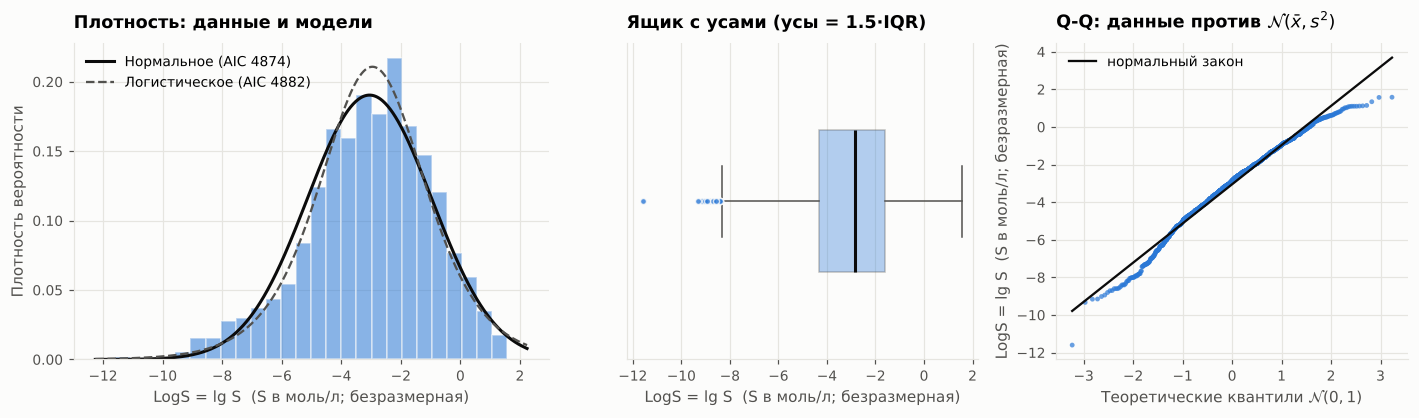

<small>**Рис. 1.** LogS: гистограмма с нормальной и логистической моделями, ящик с усами, Q-Q к нормальному закону.</small>

Проверка Z-стандартизации LogS: Mean = -0.0000, Std = 1.0000
Проверка Min-Max нормализации LogS: Min = 0.0000, Max = 1.0000


In [4]:
#@title EDA для LogS: статистики, модели распределения, нормализация
if not all(_n in globals() for _n in ('data', 'show')):
    class NeedPreviousCells(Exception):
        def _render_traceback_(self):
            return ["⚠ Эта ячейка использует результаты ячеек выше, а они ещё не выполнены.",
                    "  Colab: «Среда выполнения → Выполнить предшествующие» (Ctrl+F8) или «Выполнить все» (Ctrl+F9).",
                    "  Jupyter: «Run → Run All Above Selected Cell» или «Run All Cells»."]
    raise NeedPreviousCells()
show(describe_rv(data["LogS"], "LogS"), "Описательные статистики LogS")
fits_logs = fit_candidates(data["LogS"].values, ["Нормальное", "Логистическое"])
show(fits_logs.drop(columns=["_params", "_dist"]), "LogS: нормальная или логистическая модель", highlight_row=0)
eda_figure(data["LogS"].values, "LogS", models_from_fits(fits_logs),
           caption="LogS: гистограмма с нормальной и логистической моделями, ящик с усами, Q-Q к нормальному закону.")

# Z-стандартизация (приведение к стандартному нормальному N(0,1)) и Min-Max нормализация
data["LogS_Z"] = (data["LogS"] - data["LogS"].mean()) / data["LogS"].std()
data["LogS_MinMax"] = (data["LogS"] - data["LogS"].min()) / (data["LogS"].max() - data["LogS"].min())
print(f"Проверка Z-стандартизации LogS: Mean = {data['LogS_Z'].mean():.4f}, Std = {data['LogS_Z'].std():.4f}")
print(f"Проверка Min-Max нормализации LogS: Min = {data['LogS_MinMax'].min():.4f}, Max = {data['LogS_MinMax'].max():.4f}")

**Математическая база распределения `LogS` и его особенности:**
Распределение величины `LogS` является одновершинным (унимодальным), куполообразным и близким к **нормальному закону (распределению Гаусса)** или **логистическому распределению**:
* Плотность вероятности нормального распределения:
  $$f(x) = \frac{1}{\sigma \sqrt{2\pi}} \exp\left( -\frac{(x - \mu)^2}{2\sigma^2} \right)$$
* Функция распределения (интегральная):
  $$F(x) = \frac{1}{2} \left[ 1 + \text{erf}\left( \frac{x - \mu}{\sigma \sqrt{2}} \right) \right]$$
где математическое ожидание $\mu \approx -3.0501$, а среднеквадратическое отклонение $\sigma \approx 2.0964$ (обе величины безразмерные: `LogS` – логарифм концентрации). Наблюдается умеренная левосторонняя асимметрия ($\gamma_1 = -0.49$) и небольшой положительный эксцесс ($\gamma_2 = 0.19$): левый хвост утяжелен за счет присутствия в базе высокогидрофобных полициклических пестицидов и промышленных поллютантов с крайне низкой растворимостью ($\text{LogS} < -8$).

**Механика и мотивация приведения к стандартному нормальному распределению $\mathcal{N}(0, 1)$:**
Линейное преобразование $Z = \frac{X - \mu}{\sigma}$ центрирует случайную величину (сдвигает среднее в $0$) и нормирует ее разброс на единицу ($\sigma_Z = 1$). В хемоинформатике это необходимо для устранения размерности при построении регрессионных моделей QSAR, чтобы признаки с большими абсолютными числами (например, молекулярная масса в сотнях г/моль) не подавляли вклад логарифма растворимости.

По AIC нормальная модель чуть лучше логистической (4874 против 4882), но критерий Колмогорова–Смирнова нормальную отвергает ($p = 0.03$), а логистическую нет ($p = 0.26$). Поэтому во втором спринте генератор строится для обеих моделей.

<a id="rv01-ind"></a>

### 1.1.3 Independence & Estimations

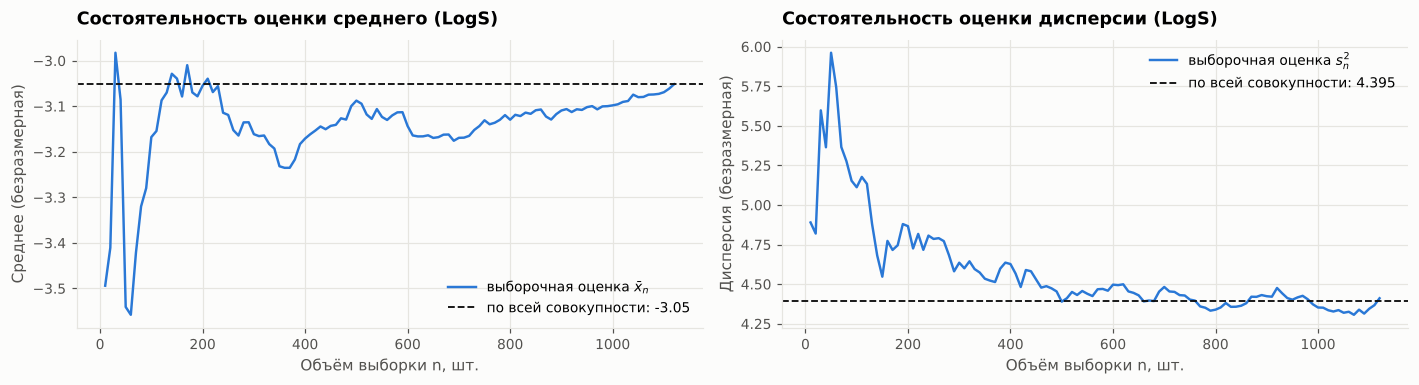

<small>**Рис. 2.** LogS: выборочные среднее и дисперсия по первым n молекулам перемешанного датасета сходятся к значениям по совокупности.</small>

Статистика,Генеральная совокупность (N = 1128),Выборка БЕЗ возвращения (n = 250),Выборка С возвращением (n = 250)
Среднее x̄,-3.0501,-3.1191,-3.1231
Медиана,-2.8600,-2.6880,-2.8500
Дисперсия s²,4.3951,4.7854,5.4065
СКО s,2.0964,2.1876,2.3252
Асимметрия γ₁,-0.4924,-0.5965,-0.6285
Эксцесс γ₂,0.1900,-0.0851,0.3753


Нулевая гипотеза H₀,Критерий,Статистика,p-value,Решение (α = 0.05)
LogS и MW независимы,Пирсон r,-0.6402,4.209e-131,H₀ отвергается
LogS и MW независимы,Спирмен ρₛ,-0.6777,1.525e-152,H₀ отвергается
LogS распределена нормально,Шапиро–Уилк W,0.9835,5.189e-10,H₀ отвергается
Средние LogS лёгких (MW < 200) и тяжёлых (MW ≥ 200) молекул равны,t-критерий Стьюдента,23.15,2.805e-97,H₀ отвергается


Среднее LogS лёгких молекул: -1.975, тяжёлых: -4.367


In [5]:
#@title Зависимость, состоятельность оценок, выборки и гипотезы для LogS
if not all(_n in globals() for _n in ('data', 'show')):
    class NeedPreviousCells(Exception):
        def _render_traceback_(self):
            return ["⚠ Эта ячейка использует результаты ячеек выше, а они ещё не выполнены.",
                    "  Colab: «Среда выполнения → Выполнить предшествующие» (Ctrl+F8) или «Выполнить все» (Ctrl+F9).",
                    "  Jupyter: «Run → Run All Above Selected Cell» или «Run All Cells»."]
    raise NeedPreviousCells()
r_mw, p_mw = stats.pearsonr(data["LogS"], data["MW"])
rho_mw, ps_mw = stats.spearmanr(data["LogS"], data["MW"])
analyze_estimations_and_samples(data["LogS"], "LogS")

w_stat, p_shapiro = stats.shapiro(data["LogS"])
light_logs = data[data["MW"] < 200]["LogS"]
heavy_logs = data[data["MW"] >= 200]["LogS"]
t_stat, p_ttest = stats.ttest_ind(light_logs, heavy_logs)
hyp_table([
    ("LogS и MW независимы", "Пирсон r", r_mw, p_mw),
    ("LogS и MW независимы", "Спирмен ρₛ", rho_mw, ps_mw),
    ("LogS распределена нормально", "Шапиро–Уилк W", w_stat, p_shapiro),
    ("Средние LogS лёгких (MW < 200) и тяжёлых (MW ≥ 200) молекул равны", "t-критерий Стьюдента", t_stat, p_ttest),
], "Проверка гипотез для LogS")
print(f"Среднее LogS лёгких молекул: {light_logs.mean():.3f}, тяжёлых: {heavy_logs.mean():.3f}")

**Выводы по `LogS`**

Растворимость, как и ожидалось, падает с ростом массы молекулы: $r = -0.64$, $\rho_S = -0.68$. Гипотезу о независимости `LogS` и `MW` отвергаем ($p \ll 0.05$). Это логично: чем больше углеродный скелет, тем хуже молекула смешивается с водой.

Оценки среднего и дисперсии ведут себя так, как положено состоятельным оценкам: при маленьких $n$ они сильно скачут, а к $n = 1128$ выходят на значения по всему датасету ($\mu = -3.05$, $\sigma^2 = 4.40$). На выборках по 250 молекул обе схемы дали похожий результат. Бесповторная оказалась ближе к совокупности по дисперсии ($4.79$ против $5.41$) и асимметрии, зато медиану лучше угадала выборка с возвращением. По одной выборке объявлять победителя рано.

Строго нормальной `LogS` не является: тест Шапиро–Уилка это отвергает ($p \approx 5 \cdot 10^{-10}$), мешает длинный левый хвост плохо растворимых веществ. Зато разница между лёгкими и тяжёлыми молекулами огромная. У молекул легче 200 г/моль среднее `LogS` равно $-1.97$, у тяжёлых $-4.37$ ($t = 23.15$, $p \ll 0.05$). Это 2.4 порядка: лёгкие молекулы в среднем растворяются примерно в 250 раз лучше.

[↑ к оглавлению](#toc)

---

<a id="rv02"></a>

## 1.2 Random Variable 02 (MW – молекулярная масса)

<a id="rv02-desc"></a>

### 1.2.1 Description
**Физико-химический смысл:** `MW` (*Molecular Weight*, г/моль) – сумма атомных масс всех элементов, входящих в брутто-формулу органической молекулы.

**Доказательство стохастической природы данных:**
Хотя для одного заранее известного индивидуального вещества молекулярная масса является константой, в нашем исследовании элементарным случайным исходом $\omega \in \Omega$ является **случайный выбор молекулы из обширной хемобиблиотеки (генеральной совокупности органических веществ)**. До момента выбора структура соединения неизвестна, а длины углеродных цепей, число ароматических колец и гетероатомов варьируются случайным образом. Поэтому на пространстве объектов датасета `MW` является непрерывной случайной величиной, которую невозможно вычислить детерминированной формулой без знания структуры.

<a id="rv02-eda"></a>

### 1.2.2 EDA & Distribution

Статистика,Значение,Ед. изм.
Объём выборки n,1128,шт.
Пропущенные значения,0,шт.
Среднее x̄,203.9,г/моль
Медиана,182.2,г/моль
Мода,102.2,г/моль
Дисперсия s²,1.056e+04,(г/моль)²
СКО s,102.7,г/моль
Коэф. вариации s / |x̄|,0.5038,–
Минимум,16.04,г/моль
Квартиль Q₁,121.2,г/моль


Распределение,Параметров k,AIC,КС: D,КС: p-value,Вывод (α = 0.05)
Гамма,2,1.344e+04,0.04728,0.01248,отвергается
Логнормальное,2,1.347e+04,0.05323,0.003222,отвергается
Нормальное,2,1.365e+04,0.09455,3.155e-09,отвергается


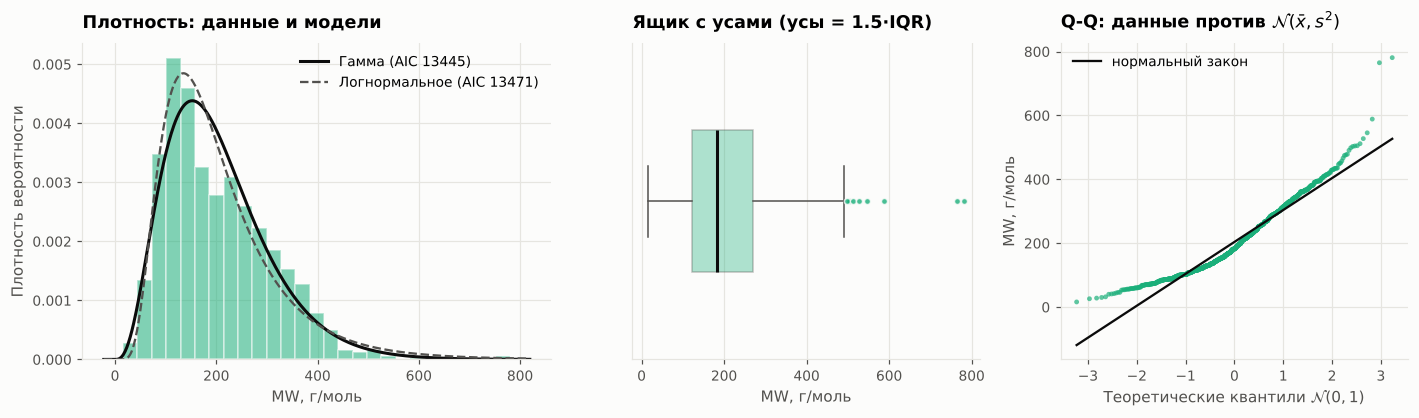

<small>**Рис. 3.** MW: гистограмма с логнормальной и гамма-моделями, ящик с усами, Q-Q к нормальному закону.</small>

In [6]:
#@title EDA для MW: статистики, модели распределения, нормализация
if not all(_n in globals() for _n in ('data', 'show')):
    class NeedPreviousCells(Exception):
        def _render_traceback_(self):
            return ["⚠ Эта ячейка использует результаты ячеек выше, а они ещё не выполнены.",
                    "  Colab: «Среда выполнения → Выполнить предшествующие» (Ctrl+F8) или «Выполнить все» (Ctrl+F9).",
                    "  Jupyter: «Run → Run All Above Selected Cell» или «Run All Cells»."]
    raise NeedPreviousCells()
show(describe_rv(data["MW"], "MW"), "Описательные статистики MW")
fits_mw = fit_candidates(data["MW"].values, ["Логнормальное", "Гамма", "Нормальное"], floc=0)
show(fits_mw.drop(columns=["_params", "_dist"]), "MW: сравнение моделей (логнормальная и гамма – с нулевым сдвигом)", highlight_row=0)
eda_figure(data["MW"].values, "MW", models_from_fits(fits_mw),
           caption="MW: гистограмма с логнормальной и гамма-моделями, ящик с усами, Q-Q к нормальному закону.")

# Нормализация и стандартизация MW
data["MW_Z"] = (data["MW"] - data["MW"].mean()) / data["MW"].std()
data["MW_MinMax"] = (data["MW"] - data["MW"].min()) / (data["MW"].max() - data["MW"].min())

**Математическая база распределения `MW` и его особенности:**
Молекулярная масса строго положительна ($\text{MW} > 0$) и обладает выраженной **правосторонней асимметрией** ($\gamma_1 = 0.91 > 0$). В органической химии преобладают малые и средние молекулы ($\mu = 203.9\text{ г/моль}$, медиана $182.2\text{ г/моль}$), тогда как крупные тяжелые структуры ($\text{MW} > 500\text{ г/моль}$) встречаются редко, образуя длинный правый хвост. Такое поведение описывается **логнормальным распределением** или **гамма-распределением**:
$$f(x) = \frac{1}{x \sigma_{\ln} \sqrt{2\pi}} \exp\left( -\frac{(\ln x - \mu_{\ln})^2}{2\sigma_{\ln}^2} \right), \quad x > 0$$
где $\mu_{\ln}$ и $\sigma_{\ln}$ – среднее и стандартное отклонение натурального логарифма молекулярной массы.

<a id="rv02-ind"></a>

### 1.2.3 Independence & Estimations

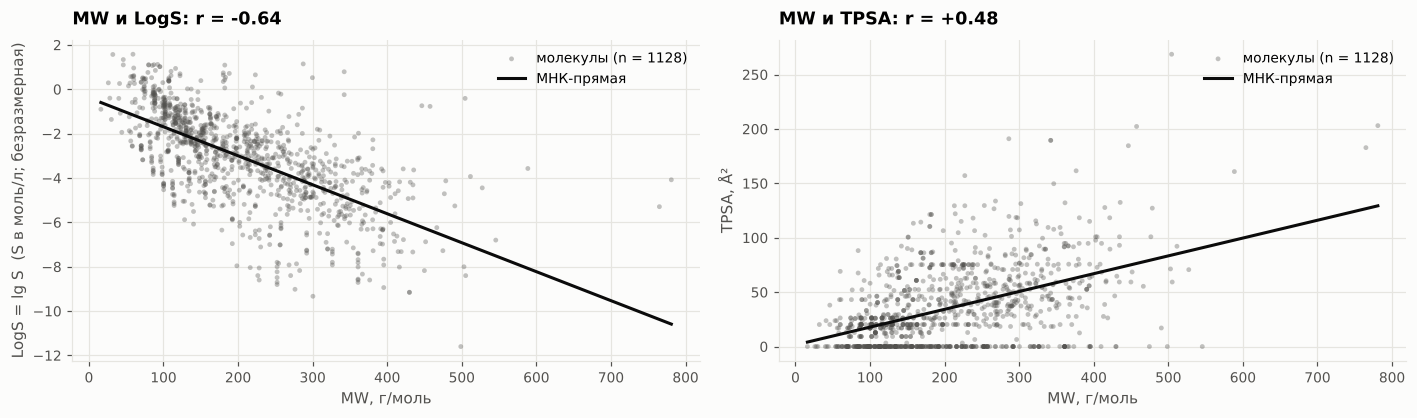

<small>**Рис. 4.** Линейная регрессия и корреляция: MW против LogS (слева) и MW против TPSA (справа).</small>

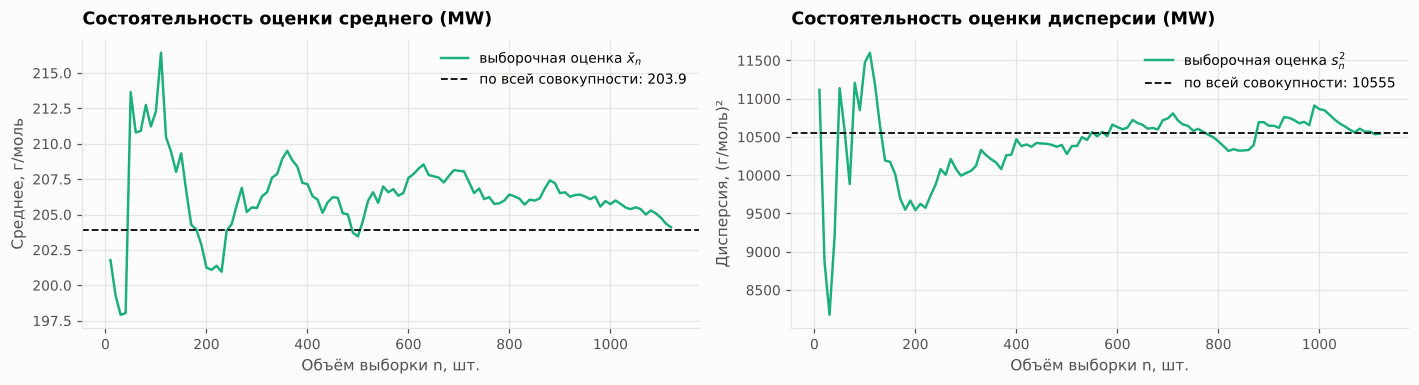

<small>**Рис. 5.** MW: выборочные среднее и дисперсия по первым n молекулам перемешанного датасета сходятся к значениям по совокупности.</small>

Статистика,Генеральная совокупность (N = 1128),Выборка БЕЗ возвращения (n = 250),Выборка С возвращением (n = 250)
Среднее x̄,203.9371,204.3177,206.6088
Медиана,182.1790,186.0520,183.6820
Дисперсия s²,10555.1125,10080.7626,10143.8070
СКО s,102.7381,100.4030,100.7165
Асимметрия γ₁,0.9071,0.7700,0.6396
Эксцесс γ₂,1.2533,0.1048,-0.3268


Нулевая гипотеза H₀,Критерий,Статистика,p-value,Решение (α = 0.05)
MW и TPSA независимы,Пирсон r,0.4754,1.11e-64,H₀ отвергается
MW и TPSA независимы,Спирмен ρₛ,0.4383,3.718e-54,H₀ отвергается
MW распределена логнормально,Колмогоров–Смирнов D,0.05323,0.003222,H₀ отвергается


In [7]:
#@title Зависимость, состоятельность оценок, выборки и гипотезы для MW
if not all(_n in globals() for _n in ('data', 'show')):
    class NeedPreviousCells(Exception):
        def _render_traceback_(self):
            return ["⚠ Эта ячейка использует результаты ячеек выше, а они ещё не выполнены.",
                    "  Colab: «Среда выполнения → Выполнить предшествующие» (Ctrl+F8) или «Выполнить все» (Ctrl+F9).",
                    "  Jupyter: «Run → Run All Above Selected Cell» или «Run All Cells»."]
    raise NeedPreviousCells()
r_mw_tpsa, p_mw_tpsa = stats.pearsonr(data["MW"], data["TPSA"])
rho_mw_tpsa, ps_mw_tpsa = stats.spearmanr(data["MW"], data["TPSA"])

fig, ax = plt.subplots(1, 2, figsize=(13, 3.9))
for a_, ycol in [(ax[0], "LogS"), (ax[1], "TPSA")]:
    x_, y_ = data["MW"].values, data[ycol].values
    b_, k0 = np.polyfit(x_, y_, 1)
    r_ = stats.pearsonr(x_, y_).statistic
    a_.scatter(x_, y_, s=10, color=STYLE["ink2"], alpha=0.35, edgecolor="none", label=f"молекулы (n = {len(x_)})")
    g_ = np.linspace(x_.min(), x_.max(), 100)
    a_.plot(g_, k0 + b_ * g_, color=STYLE["ink"], linewidth=2, label="МНК-прямая")
    a_.set_title(f"MW и {ycol}: r = {r_:+.2f}")
    a_.set_xlabel(VARS["MW"]["axis"]); a_.set_ylabel(VARS[ycol]["axis"]); a_.legend(loc="upper right")
fig.tight_layout(); plt.show()
fig_caption("Линейная регрессия и корреляция: MW против LogS (слева) и MW против TPSA (справа).")

analyze_estimations_and_samples(data["MW"], "MW")

shape, loc, scale = stats.lognorm.fit(data["MW"], floc=0)
ks_res = stats.kstest(data["MW"], stats.lognorm(shape, loc, scale).cdf)
hyp_table([
    ("MW и TPSA независимы", "Пирсон r", r_mw_tpsa, p_mw_tpsa),
    ("MW и TPSA независимы", "Спирмен ρₛ", rho_mw_tpsa, ps_mw_tpsa),
    ("MW распределена логнормально", "Колмогоров–Смирнов D", ks_res.statistic, ks_res.pvalue),
], "Проверка гипотез для MW")

**Выводы по `MW`**

Масса и полярная площадь связаны слабее, чем можно было ожидать: $r = 0.48$, $\rho_S = 0.44$. Независимость отвергается ($p \ll 0.05$), но связь средняя. Это понятно: в большой молекуле есть место для полярных групп с азотом и кислородом, но она может оказаться и почти чистым углеводородом.

Среднее и дисперсия `MW` сходятся к значениям по совокупности ($\mu = 203.9$ г/моль, $\sigma = 102.7$ г/моль). На выборках по 250 молекул бесповторная точнее угадала среднее ($204.3$ против $206.6$), а выборка с возвращением – медиану и дисперсию. Так что и здесь явного победителя нет.

Гипотезу о логнормальном законе критерий Колмогорова–Смирнова отверг ($D = 0.053$, $p = 0.003$). На глаз гистограмма на него похожа, и по AIC логнормальная и гамма-модели почти равны (у гаммы чуть лучше: 13 445 против 13 471, но КС отвергает и её, $p = 0.012$). При 1128 молекулах тест замечает расхождения в хвостах, поэтому честнее говорить «похоже на логнормальное», чем «логнормальное».

[↑ к оглавлению](#toc)

---

<a id="rv03"></a>

## 1.3 Random Variable 03 (TPSA – топологическая полярная площадь поверхности)

<a id="rv03-desc"></a>

### 1.3.1 Description
**Физико-химический смысл:** `TPSA` (*Topological Polar Surface Area*, $\text{\AA}^2$) – суммарная площадь поверхности полярных атомов молекулы (преимущественно кислорода, азота и связанных с ними атомов водорода). Этот дескриптор определяет способность молекулы образовывать водородные связи с водой и проникать сквозь клеточные мембраны.

**Доказательство стохастической природы данных:**
Как и молекулярная масса, величина `TPSA` задана на вероятностном пространстве химических структур датасета. При случайном выборе соединения количество и тип полярных функциональных групп (гидроксильных, карбонильных, аминогрупп) варьируются стохастически. Кроме того, само значение `TPSA` вычисляется по методу Эртля как сумма статистических инкрементов фрагментов без учета реальной трехмерной конформационной динамики молекулы в растворе, что вносит дополнительную аппроксимационную неопределенность.

<a id="rv03-eda"></a>

### 1.3.2 EDA & Distribution

Статистика,Значение,Ед. изм.
Объём выборки n,1128,шт.
Пропущенные значения,0,шт.
Среднее x̄,34.87,Å²
Медиана,26.3,Å²
Мода,0,Å²
Дисперсия s²,1252,(Å²)²
СКО s,35.38,Å²
Коэф. вариации s / |x̄|,1.015,–
Минимум,0,Å²
Квартиль Q₁,0,Å²


Молекул с TPSA = 0: 314 из 1128 (p₀ = 0.278); среднее положительной части x̄₊ = 48.33 Å²


Распределение,Параметров k,AIC,КС: D,КС: p-value,Вывод (α = 0.05)
Логнормальное,2,7648,0.09864,2.397e-07,отвергается
Гамма,2,7658,0.1001,1.509e-07,отвергается
Экспоненциальное,1,7943,0.2288,6.189e-38,отвергается


Логнормальная часть: σ = 0.683, медиана e^μ = 38.8 Å²;  экспоненциальная: λ = 1/x̄₊ = 0.0207 Å⁻²


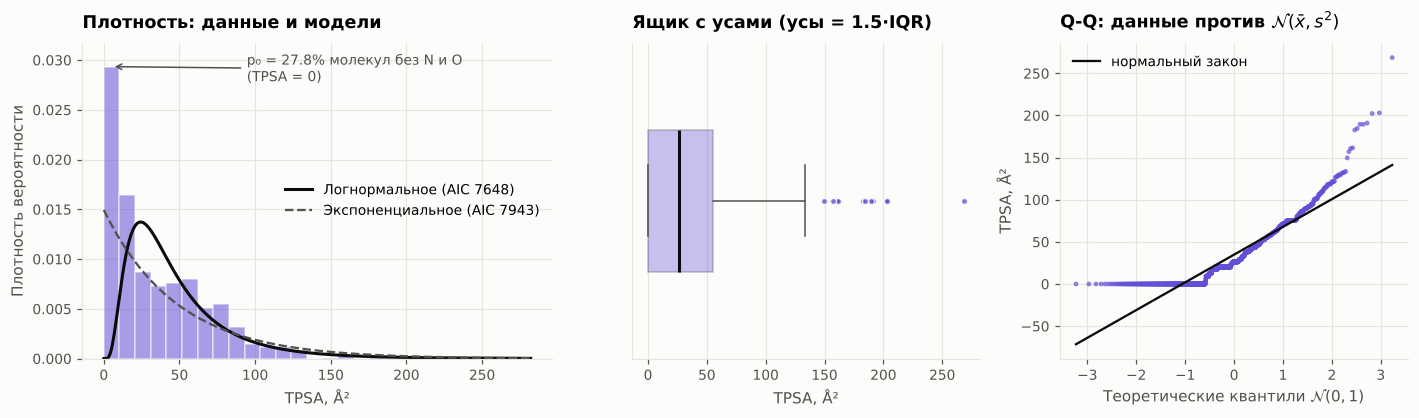

<small>**Рис. 6.** TPSA: гистограмма со смешанными моделями (1 − p₀)·g(x), ящик с усами, Q-Q к нормальному закону.</small>

In [8]:
#@title EDA для TPSA: статистики, смешанное распределение (нули + непрерывная часть)
if not all(_n in globals() for _n in ('data', 'show')):
    class NeedPreviousCells(Exception):
        def _render_traceback_(self):
            return ["⚠ Эта ячейка использует результаты ячеек выше, а они ещё не выполнены.",
                    "  Colab: «Среда выполнения → Выполнить предшествующие» (Ctrl+F8) или «Выполнить все» (Ctrl+F9).",
                    "  Jupyter: «Run → Run All Above Selected Cell» или «Run All Cells»."]
    raise NeedPreviousCells()
x_tpsa = data["TPSA"].values
show(describe_rv(data["TPSA"], "TPSA"), "Описательные статистики TPSA")
p0 = (x_tpsa == 0).mean()
pos = x_tpsa[x_tpsa > 0]
print(f"Молекул с TPSA = 0: {(x_tpsa == 0).sum()} из {len(x_tpsa)} (p₀ = {p0:.3f}); среднее положительной части x̄₊ = {pos.mean():.2f} Å²")
fits_tpsa = fit_candidates(pos, ["Логнормальное", "Гамма", "Экспоненциальное"], floc=0)
show(fits_tpsa.drop(columns=["_params", "_dist"]), "TPSA > 0: сравнение моделей для непрерывной части", highlight_row=0)
s_ln, _, scale_ln = fits_tpsa.loc[fits_tpsa["Распределение"] == "Логнормальное", "_params"].iloc[0]
print(f"Логнормальная часть: σ = {s_ln:.3f}, медиана e^μ = {scale_ln:.1f} Å²;  экспоненциальная: λ = 1/x̄₊ = {1 / pos.mean():.4f} Å⁻²")
eda_figure(x_tpsa, "TPSA", models_from_fits(fits_tpsa.sort_values("AIC").iloc[[0, 2]], scale=1 - p0),
           annotate_zero=f"p₀ = {p0:.1%} молекул без N и O\n(TPSA = 0)",
           caption="TPSA: гистограмма со смешанными моделями (1 − p₀)·g(x), ящик с усами, Q-Q к нормальному закону.")

# Нормализация и стандартизация TPSA
data["TPSA_Z"] = (data["TPSA"] - data["TPSA"].mean()) / data["TPSA"].std()
data["TPSA_MinMax"] = (data["TPSA"] - data["TPSA"].min()) / (data["TPSA"].max() - data["TPSA"].min())

**Математическая база распределения `TPSA` и его особенности:**
Величина `TPSA` ограничена слева нулем ($\text{TPSA} \ge 0$). Мода распределения равна $0\text{ \AA}^2$ – это чистые углеводороды и галогенпроизводные (бензол, алкены, алканы), вовсе не имеющие полярных атомов $O$ и $N$. Распределение характеризуется сильной правосторонней асимметрией ($\gamma_1 = 1.45$) и высоким положительным эксцессом ($\gamma_2 = 3.51$). Ноль здесь не просто мода: у 314 молекул из 1128 ($27.8\%$) `TPSA` равна нулю точно. Поэтому распределение **смешанное** – атом вероятности в нуле плюс непрерывная часть:
$$F(x) = p_0 + (1 - p_0)\,G(x), \quad x \ge 0, \qquad p_0 = P(\text{TPSA} = 0) \approx 0.278 .$$
Для непрерывной части $G$ сравнивались три модели (таблица выше). Экспоненциальная $g(x) = \lambda e^{-\lambda x}$ с $\lambda = 1/\bar{x}_{+} \approx 1/48.3 \approx 0.0207\ \text{\AA}^{-2}$ описывает её хуже всех (AIC $7943$). Лучшая – логнормальная (AIC $7648$, медиана $e^{\mu} \approx 38.8\ \text{\AA}^2$), хотя критерий КС отвергает и её.

<a id="rv03-ind"></a>

### 1.3.3 Independence & Estimations

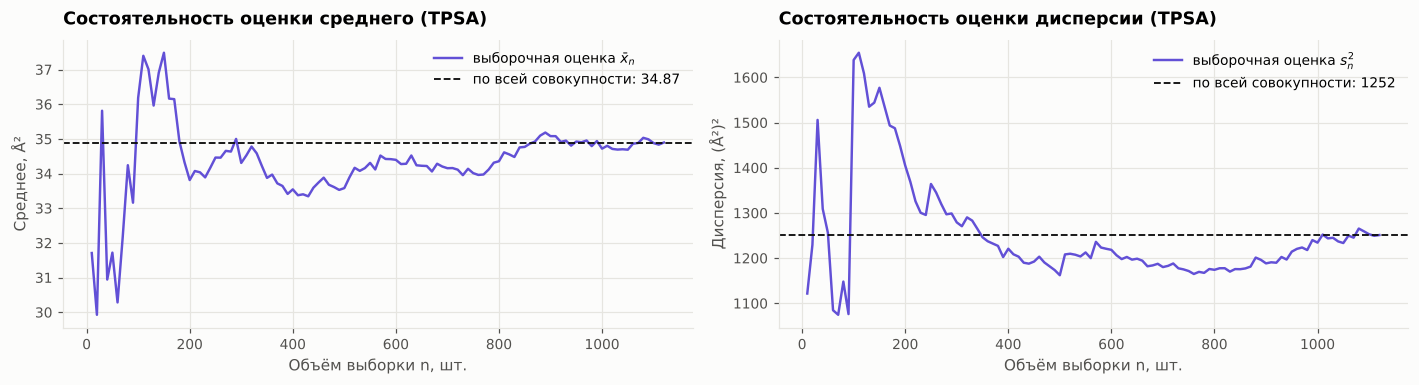

<small>**Рис. 7.** TPSA: выборочные среднее и дисперсия по первым n молекулам перемешанного датасета сходятся к значениям по совокупности.</small>

Статистика,Генеральная совокупность (N = 1128),Выборка БЕЗ возвращения (n = 250),Выборка С возвращением (n = 250)
Среднее x̄,34.8729,34.4608,35.7805
Медиана,26.3000,25.9000,26.1600
Дисперсия s²,1251.9986,1364.0819,1253.3050
СКО s,35.3836,36.9335,35.4020
Асимметрия γ₁,1.4522,1.8422,1.0625
Эксцесс γ₂,3.5092,6.4440,0.9379


Нулевая гипотеза H₀,Критерий,Статистика,p-value,Решение (α = 0.05)
TPSA и LogS независимы,Пирсон r,0.1232,3.335e-05,H₀ отвергается
TPSA и LogS независимы,Спирмен ρₛ,0.1119,0.000165,H₀ отвергается
LogS у неполярных (TPSA = 0) и полярных (TPSA > 0) молекул распределена одинаково,U-критерий Манна–Уитни,7.825e+04,5.342e-24,H₀ отвергается


Медиана LogS неполярных: -3.815, полярных: -2.487


In [9]:
#@title Зависимость, состоятельность оценок, выборки и гипотезы для TPSA
if not all(_n in globals() for _n in ('data', 'show')):
    class NeedPreviousCells(Exception):
        def _render_traceback_(self):
            return ["⚠ Эта ячейка использует результаты ячеек выше, а они ещё не выполнены.",
                    "  Colab: «Среда выполнения → Выполнить предшествующие» (Ctrl+F8) или «Выполнить все» (Ctrl+F9).",
                    "  Jupyter: «Run → Run All Above Selected Cell» или «Run All Cells»."]
    raise NeedPreviousCells()
r_tpsa_logs, p_tpsa_logs = stats.pearsonr(data["TPSA"], data["LogS"])
rho_tpsa_logs, ps_tpsa_logs = stats.spearmanr(data["TPSA"], data["LogS"])
analyze_estimations_and_samples(data["TPSA"], "TPSA")

non_polar = data[data["TPSA"] == 0]["LogS"]
polar = data[data["TPSA"] > 0]["LogS"]
u_stat, p_mann = stats.mannwhitneyu(non_polar, polar)
hyp_table([
    ("TPSA и LogS независимы", "Пирсон r", r_tpsa_logs, p_tpsa_logs),
    ("TPSA и LogS независимы", "Спирмен ρₛ", rho_tpsa_logs, ps_tpsa_logs),
    ("LogS у неполярных (TPSA = 0) и полярных (TPSA > 0) молекул распределена одинаково", "U-критерий Манна–Уитни", u_stat, p_mann),
], "Проверка гипотез для TPSA")
print(f"Медиана LogS неполярных: {non_polar.median():.3f}, полярных: {polar.median():.3f}")

**Выводы по `TPSA`**

Связь полярной площади с растворимостью оказалась слабой: $r = 0.12$, $\rho_S = 0.11$. Формально она значима ($p < 0.001$), но объясняет всего около 1.5 % разброса `LogS`. Одной полярностью растворимость не объяснить, масса важнее.

Среднее и дисперсия снова сходятся к значениям по совокупности ($\mu = 34.87$ Å², $\sigma^2 = 1252$). А вот эксцесс на выборке из 250 молекул прыгает: $6.44$ без возвращения и $0.94$ с возвращением, при $3.51$ на всём датасете. Он зависит от того, попали ли в выборку несколько очень полярных молекул из хвоста.

Интереснее всего сравнение групп. Молекулы совсем без полярных групп (`TPSA` = 0) растворяются заметно хуже остальных: медиана `LogS` у них $-3.815$ против $-2.487$, это примерно в 20 раз. U-критерий Манна–Уитни показывает, что разница не случайна ($p \approx 5 \cdot 10^{-24}$).


[↑ к оглавлению](#toc)

<a id="s1-resume"></a>

## 1.4 Lab resume

Мы разобрали три величины из датасета ESOL (1128 органических соединений), и вот что получилось.

1. **Все три величины случайные, но устроены по-разному.** `LogS` близка к нормальному и логистическому закону ($\mu = -3.05$, $\sigma = 2.10$), только с длинным левым хвостом. `MW` похожа на логнормальную или гамма ($\mu = 203.9$ г/моль), хотя тест КС формально отвергает обе модели. `TPSA` оказалась смешанной: у 27.8 % молекул она ровно ноль, остальная часть похожа на логнормальное распределение.
2. **Растворимость сильнее всего связана с массой.** Из наших трёх величин с `LogS` сильнее всего коррелирует `MW` ($r = -0.64$): лёгкие молекулы растворяются примерно в 250 раз лучше тяжёлых. Это согласуется со статьёй Делани (2004), где масса входит в уравнение ESOL. Но кроме массы там есть липофильность clogP, число вращающихся связей и доля ароматических атомов, а clogP мы не анализировали. Поэтому утверждать, что масса – главный предиктор, по нашим данным нельзя. Полярность влияет слабее: молекулы совсем без полярных групп растворяются в среднем примерно в 20 раз хуже остальных.
3. **Оценки состоятельны.** С ростом $n$ выборочные среднее и дисперсия сходятся к значениям по всему датасету. Выборки по 250 молекул с возвращением и без дали близкие результаты. Теоретически бесповторная точнее (дисперсия оценки среднего меньше в $(N-n)/(N-1) \approx 0.78$ раза), но на одной выборке этого почти не видно.

<a id="s1-cat"></a>

### 1.4.1 cat_mark_table
| cat_id | notebook_link | coeff | comment |
|--------|---------------|-------|---------|
| `RV_01_LogS` | [1.1 LogS](#rv01) | 1.0 | Доказана случайность, полный EDA в таблице, Z-стандартизация к N(0,1), состоятельность, гипотезы Шапиро-Уилка и Стьюдента |
| `RV_02_MW` | [1.2 MW](#rv02) | 1.0 | Анализ логнормального распределения молекулярной массы, корреляция с LogS и TPSA, тест Колмогорова-Смирнова |
| `RV_03_TPSA` | [1.3 TPSA](#rv03) | 1.0 | Анализ асимметричного распределения TPSA, непараметрический тест Манна-Уитни |
| `BONUS_S1` | [1.4 Lab resume](#s1-resume) | 1.5 | Табличное представление всех метрик, приведение к стандартному нормальному распределению с мотивацией, сопоставление со статьей Делани |


[↑ к оглавлению](#toc)

---

<a id="s2"></a>

# 2. Lab01 - sprint 2

*Авторы раздела: Мамедгасанов Гашам, Дрожжина Анна, Михайлова Мария (Инфохимия)*

<a id="gen01"></a>

## 2.1 random 01 (Синтез генератора случайных чисел для величины LogS)

<a id="gen01-desc"></a>

### 2.1.1 Description
Целью второго спринта является разработка собственного программного генератора псевдослучайных чисел (ГСЧ), способного моделировать экспериментальную растворимость молекул `LogS` без использования встроенных библиотечных функций генерации целевых распределений (`scipy.stats`, `np.random.normal`). В качестве фундамента используется исключительно базовый равномерный датчик $U \sim \mathcal{U}(0, 1)$ на базе алгоритма **«Вихрь Мерсенна» (Mersenne Twister MT19937)**.

Для получения дополнительных баллов и глубокого сравнения мы реализуем сразу **два классических математических подхода**:
1. **Метод полярных координат Марсальи (Polar Method)** – для генерации нормального распределения $\mathcal{N}(\mu, \sigma^2)$.
2. **Метод обратной функции (Квантильное преобразование / Inverse Transform Sampling)** – для генерации логистического распределения $\text{Logistic}(\mu, s)$, которое еще точнее описывает тяжелые хвосты растворимости.

---

<a id="gen01-math"></a>

### 2.1.2 math desc

#### 1. Математическое обоснование метода полярных координат Марсальи (Д. Кнут, Том 2)
Классическое преобразование Бокса-Мюллера переводит пару независимых равномерных величин $U_1, U_2 \sim \mathcal{U}(0, 1)$ в пару независимых стандартных нормальных величин $Z_1, Z_2 \sim \mathcal{N}(0, 1)$ через полярные координаты $R = \sqrt{-2\ln U_1}$ и $\theta = 2\pi U_2$. Однако вычисление тригонометрических функций $\cos\theta$ и $\sin\theta$ на процессоре является ресурсоемким.

Джордж Марсалья предложил исключить тригонометрию методом отбора точки внутри единичного круга:
1. Генерируются два независимых равномерных числа $U_1, U_2 \sim \mathcal{U}(0, 1)$ и линейно отображаются на квадрат $[-1, 1] \times [-1, 1]$:
   $$V_1 = 2U_1 - 1, \quad V_2 = 2U_2 - 1$$
2. Вычисляется квадрат радиус-вектора точки от начала координат:
   $$S = V_1^2 + V_2^2$$
3. Если $S \ge 1$ или $S = 0$ (точка попала вне единичного круга), пара отбрасывается, и шаг 1 повторяется. Вероятность успешного попадания внутрь круга равна отношению площади круга к площади описанного квадрата: $P(S < 1) = \frac{\pi}{4} \approx 78.54\%$.
4. При условии $0 < S < 1$ величина $S$ распределена равномерно на $(0, 1)$, а отношения $\frac{V_1}{\sqrt{S}}$ и $\frac{V_2}{\sqrt{S}}$ точно равны $\cos\theta$ и $\sin\theta$ случайного угла! Подставляя их в формулу Бокса-Мюллера, получаем две независимые стандартные нормальные величины:
   $$Z_1 = V_1 \sqrt{\frac{-2 \ln S}{S}}, \quad Z_2 = V_2 \sqrt{\frac{-2 \ln S}{S}}$$
5. Переход к масштабу нашей химической величины `LogS` с математическим ожиданием $\mu$ и стандартным отклонением $\sigma$ осуществляется аффинным сдвигом:
   $$X = \mu + \sigma \cdot Z$$

#### 2. Математическое обоснование метода обратной функции (С. М. Ермаков)
Пусть непрерывная случайная величина $X$ имеет строго возрастающую функцию распределения $F(x) = P(X \le x)$. По теореме о квантильном преобразовании, если $U \sim \mathcal{U}(0, 1)$, то случайная величина $X = F^{-1}(U)$ имеет функцию распределения $F(x)$, так как:
$$P(F^{-1}(U) \le x) = P(U \le F(x)) = F(x)$$
Аппроксимируем распределение `LogS` логистическим законом с центром $\mu$ и параметром масштаба $s = \frac{\sigma \sqrt{3}}{\pi}$, функция распределения которого имеет аналитический вид:
$$F(x) = \frac{1}{1 + \exp\left(-\frac{x - \mu}{s}\right)}$$
Приравнивая $F(x) = U$ и выражая $x$ через элементарные алгебраические преобразования, получаем явную формулу датчика:
$$\frac{1}{1 + e^{-(x - \mu)/s}} = U \implies e^{-(x - \mu)/s} = \frac{1 - U}{U} \implies X = \mu + s \cdot \ln\left(\frac{U}{1 - U}\right)$$

---

<a id="gen01-algos"></a>

#### Исследование алгоритмов датчиков случайных чисел (Дополнительные баллы: обзор 8 методов)

| № | Алгоритм датчика | Тип распределения | Где используется | Сильные стороны | Слабые стороны | Литературный источник |
|---|---|---|---|---|---|---|
| 1 | **Вихрь Мерсенна (MT19937)** | Равномерное $\mathcal{U}(0,1)$ | Базовый ГСЧ в Python, R, MATLAB, C++ | Колоссальный период $2^{19937}-1$, высокая скорость, 623-мерная равномерность | Не является криптостойким, большой объем состояния (2.5 КБ) | Matsumoto & Nishimura (1998), *ACM TOMACS* |
| 2 | **Метод обратной функции (Квантильное преобр.)** | Показательное, Вейбулла, Коши, Логистическое | Моделирование времени жизни радионуклидов, кинетика реакций | 100% эффективность (нет отбрасывания точек), взаимно-однозначное соответствие с $U$ | Требует аналитически обратимой функции $F^{-1}(u)$ (неприменим напрямую к Гауссу) | Ермаков С. М. (1982), Глава 1 |
| 3 | **Метод полярных координат Марсальи** | Нормальное $\mathcal{N}(\mu, \sigma^2)$ | Молекулярная динамика (термостат Ланжевена), хемометрика | Не требует медленных вызовов $\sin$ и $\cos$, генерирует сразу 2 числа | Отбрасывает $\approx 21.46\%$ точек ($1 - \pi/4$), использует логарифм и корень | Кнут Д. Э. (2019), Том 2, Раздел 3.4.1 (Алгоритм P) |
| 4 | **Метод отбора Неймана (Acceptance-Rejection)** | Любое непрерывное со сложной плотностью $f(x)$ | Квантовая химия (выборка по волновым функциям методом Монте-Карло) | Универсален для любых плотностей, даже без известной функции распределения $F(x)$ | Низкий КПД при неудачном выборе мажорирующей функции $g(x)$ | Von Neumann J. (1951); Ермаков С. М. (1982) |
| 5 | **Метод суперпозиции (смесей)** | Сложные многомодальные распределения | Аппроксимация спектров поглощения и хроматографических пиков | Позволяет разбить сложную плотность на сумму простых $f(x) = \sum p_k f_k(x)$ | Требует предварительного расчета весов смеси $p_k$ | Ермаков С. М., Михайлов Г. А. (1982) |
| 6 | **Метод зиккурата (развитие метода прямоугольника-клина-хвоста)** | Нормальное, Показательное | Высокопроизводительные симуляции в `NumPy` (`default_rng`) | Самый быстрый алгоритм: в $98\%$ случаев обходится одним сравнением без $\ln$ и $\sqrt{}$ | Сложная реализация и необходимость хранения предвычисленных таблиц | Marsaglia G., Tsang W. W. (2000), *J. Stat. Softw.*; исходный метод – Marsaglia, MacLaren, Bray (1964), Кнут Д. Э., т. 2, 3.4.1 (алгоритм M) |
| 7 | **Метод отношений (Киндермана-Монахана)** | Нормальное, t-Стьюдента, Гамма | Статистические пакеты моделирования | Компактный код, быстрая сходимость области отношения $v/u$ | Требует деления чисел с плавающей точкой и проверки логарифмических границ | Kinderman A. J., Monahan J. F. (1977), *ACM TOMS*; Кнут Д. Э., т. 2 |
| 8 | **Метод псевдонимов Уокера (Alias Method)** | Дискретные распределения с $K$ исходами | Стохастический алгоритм Гиллеспи для химической кинетики | Генерация за константное время $\mathcal{O}(1)$ независимо от числа исходов $K$ | Требует $\mathcal{O}(K)$ времени и памяти на предварительную инициализацию таблиц | Walker A. J. (1977), *ACM TOMS*; Кнут Д. Э., т. 2 |

---

<a id="gen01-lit"></a>

#### Список использованной литературы (из фондов РГБ, РНБ, ACM, SIAM, ACS)
1. **Delaney J. S.** ESOL: Estimating Aqueous Solubility Directly from Molecular Structure // *Journal of Chemical Information and Computer Sciences (ACS)*. – 2004. – Vol. 44, No. 3. – P. 1000–1005.
2. **Кнут Д. Э.** Искусство программирования. Том 2. Получисленные алгоритмы / Пер. с англ. – 3-е изд. – М.: Издательский дом «Вильямс», 2019. – 832 с. – ISBN 978-5-8459-0081-4 (Глава 3 «Случайные числа», раздел 3.4.1).
3. **Ермаков С. М., Михайлов Г. А.** Статистическое моделирование: Учебное пособие. – 2-е изд., доп. – М.: Наука, Главная редакция физико-математической литературы, 1982. – 296 с..
4. **Marsaglia G., Bray T. A.** A Convenient Method for Generating Normal Variables // *SIAM Review*. – 1964. – Vol. 6, No. 3. – P. 260–264.
5. **Matsumoto M., Nishimura T.** Mersenne Twister: A 623-Dimensionally Equidistributed Uniform Pseudo-Random Number Generator // *ACM Transactions on Modeling and Computer Simulation (TOMACS)*. – 1998. – Vol. 8, No. 1. – P. 3–30.
6. **Kinderman A. J., Monahan J. F.** Computer Generation of Random Variables Using the Ratio of Uniform Deviates // *ACM Transactions on Mathematical Software (TOMS)*. – 1977. – Vol. 3, No. 3. – P. 257–260.
7. **Devroye L.** Non-Uniform Random Variate Generation. – New York: Springer-Verlag, 1986. – 843 p.

<a id="gen01-code"></a>

### 2.1.3 code

In [10]:
#@title Генератор InfoChemRandomGenerator: полярный метод и метод обратной функции
if not all(_n in globals() for _n in ('data',)):
    class NeedPreviousCells(Exception):
        def _render_traceback_(self):
            return ["⚠ Эта ячейка использует результаты ячеек выше, а они ещё не выполнены.",
                    "  Colab: «Среда выполнения → Выполнить предшествующие» (Ctrl+F8) или «Выполнить все» (Ctrl+F9).",
                    "  Jupyter: «Run → Run All Above Selected Cell» или «Run All Cells»."]
    raise NeedPreviousCells()
class InfoChemRandomGenerator:
    """
    Генератор случайных чисел для моделирования физико-химических параметров (LogS).
    Использует только базовый равномерный датчик U(0, 1) на основе Вихря Мерсенна (MT19937).
    """
    def __init__(self, seed=42):
        # Инициализируем классический генератор Вихрь Мерсенна (MT19937)
        bit_gen = np.random.MT19937(seed)
        self.rng = np.random.Generator(bit_gen)
        
    def generate_polar_marsaglia(self, n: int, mu: float, sigma: float) -> np.ndarray:
        """
        Алгоритм 1: Полярный метод Марсальи (Д. Кнут, том 2, Алгоритм P).
        Генерирует нормальное распределение N(mu, sigma^2) без вызовов sin/cos.
        """
        samples = []
        while len(samples) < n:
            u1, u2 = self.rng.random(2)
            v1 = 2.0 * u1 - 1.0
            v2 = 2.0 * u2 - 1.0
            s = v1 * v1 + v2 * v2
            
            if 0.0 < s < 1.0:
                factor = np.sqrt(-2.0 * np.log(s) / s)
                z1 = v1 * factor
                z2 = v2 * factor
                samples.append(mu + sigma * z1)
                if len(samples) < n:
                    samples.append(mu + sigma * z2)
        return np.array(samples, dtype=float)
    
    def generate_inverse_logistic(self, n: int, mu: float, sigma: float) -> np.ndarray:
        """
        Алгоритм 2: Метод обратной функции (квантильное преобразование) для логистического закона.
        Параметр масштаба s выражается через СКО как s = sigma * sqrt(3) / pi.
        """
        s = sigma * np.sqrt(3.0) / np.pi
        # Защита от краевых значений 0 и 1 при логарифмировании
        u = self.rng.uniform(1e-7, 1.0 - 1e-7, size=n)
        return mu + s * np.log(u / (1.0 - u))

# Генерируем синтетические выборки объема N = 1128 на основе параметров реального LogS
generator = InfoChemRandomGenerator(seed=2026)
N_real = len(data['LogS'])
mu_logs = data['LogS'].mean()
sigma_logs = data['LogS'].std()

synth_polar = generator.generate_polar_marsaglia(N_real, mu_logs, sigma_logs)
synth_logistic = generator.generate_inverse_logistic(N_real, mu_logs, sigma_logs)

print("Генерация успешно завершена! Первые 5 значений (Полярный метод):", synth_polar[:5].round(4))
print("Первые 5 значений (Метод обратной функции):                    ", synth_logistic[:5].round(4))

Генерация успешно завершена! Первые 5 значений (Полярный метод): [ 0.1437 -3.2294 -4.3798 -1.1269 -4.2682]
Первые 5 значений (Метод обратной функции):                     [-4.0048 -1.3154 -4.3767 -3.3653 -1.6027]


<a id="gen01-tests"></a>

### 2.1.4 tests

Статистическая метрика,Реальные данные (LogS),ГСЧ 1: Полярный метод Марсальи,ГСЧ 2: Метод обратной функции
Объём выборки n,1128.0000,1128.0000,1128.0000
Среднее x̄,-3.0501,-3.0752,-3.0497
Медиана,-2.8600,-3.0530,-3.0551
Дисперсия s²,4.3951,4.2876,4.8079
СКО s,2.0964,2.0706,2.1927
Минимум,-11.6000,-9.1142,-12.1272
Квартиль Q₁,-4.3175,-4.5096,-4.3435
Квартиль Q₃,-1.6000,-1.7076,-1.6628
Максимум,1.5800,3.7999,5.8782
IQR,2.7175,2.8020,2.6806


Нулевая гипотеза H₀,Критерий,Статистика,p-value,Решение (α = 0.05)
Выборка полярного метода и LogS из одного распределения,Колмогоров–Смирнов D (2 выборки),0.04787,0.1507,H₀ не отвергается
Выборка метода обратной функции и LogS из одного распределения,Колмогоров–Смирнов D (2 выборки),0.04699,0.1657,H₀ не отвергается


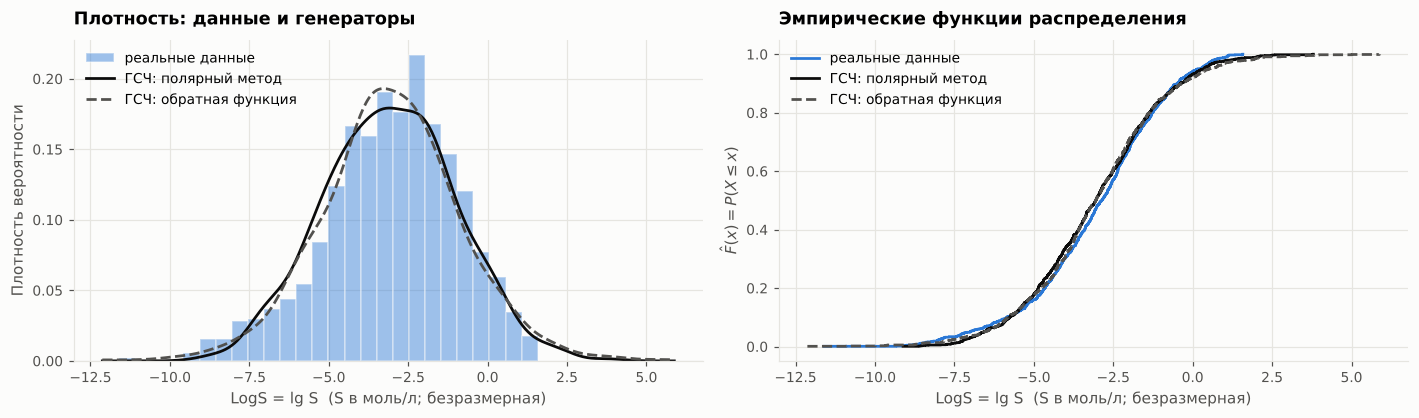

<small>**Рис. 8.** Сравнение LogS с выборками генераторов: плотности (гистограмма данных и сглаженные плотности генераторов) и эмпирические функции распределения.</small>

[ OK ] Все 5 автотестов для 'Полярный метод Марсальи' пройдены (погрешность Mean: 0.82%, Std: 1.23%, t-test p: 0.7749, KS p: 0.1507)
[ OK ] Все 5 автотестов для 'Метод обратной функции' пройдены (погрешность Mean: 0.01%, Std: 4.59%, t-test p: 0.9963, KS p: 0.1657)


In [11]:
#@title Тесты генератора: таблица метрик, графики, автотесты
if not all(_n in globals() for _n in ('synth_polar', 'synth_logistic')):
    class NeedPreviousCells(Exception):
        def _render_traceback_(self):
            return ["⚠ Эта ячейка использует результаты ячеек выше, а они ещё не выполнены.",
                    "  Colab: «Среда выполнения → Выполнить предшествующие» (Ctrl+F8) или «Выполнить все» (Ctrl+F9).",
                    "  Jupyter: «Run → Run All Above Selected Cell» или «Run All Cells»."]
    raise NeedPreviousCells()
real_vals = data["LogS"].values


def metrics(a):
    return [len(a), np.mean(a), np.median(a), np.var(a, ddof=1), np.std(a, ddof=1), np.min(a),
            np.percentile(a, 25), np.percentile(a, 75), np.max(a),
            np.percentile(a, 75) - np.percentile(a, 25), stats.skew(a), stats.kurtosis(a)]


gen_comparison_df = pd.DataFrame({
    "Статистическая метрика": ["Объём выборки n", "Среднее x̄", "Медиана", "Дисперсия s²", "СКО s", "Минимум",
                               "Квартиль Q₁", "Квартиль Q₃", "Максимум", "IQR", "Асимметрия γ₁", "Эксцесс γ₂"],
    "Реальные данные (LogS)": metrics(real_vals),
    "ГСЧ 1: Полярный метод Марсальи": metrics(synth_polar),
    "ГСЧ 2: Метод обратной функции": metrics(synth_logistic),
})
show(gen_comparison_df, "Метрики реальных данных и двух генераторов", fmt="{:.4f}")

ks_polar, ks_logistic = stats.ks_2samp(real_vals, synth_polar), stats.ks_2samp(real_vals, synth_logistic)
hyp_table([
    ("Выборка полярного метода и LogS из одного распределения", "Колмогоров–Смирнов D (2 выборки)", ks_polar.statistic, ks_polar.pvalue),
    ("Выборка метода обратной функции и LogS из одного распределения", "Колмогоров–Смирнов D (2 выборки)", ks_logistic.statistic, ks_logistic.pvalue),
], "Совпадение формы распределения: двухвыборочный критерий КС")

# Визуальное сравнение: гистограмма данных и сглаженные плотности генераторов, функции распределения
fig, ax = plt.subplots(1, 2, figsize=(13, 3.9))
bins = np.histogram_bin_edges(real_vals, bins="fd")
ax[0].hist(real_vals, bins=bins, density=True, color=VARS["LogS"]["color"], alpha=0.45, edgecolor=STYLE["surface"], label="реальные данные")
g = np.linspace(min(real_vals.min(), synth_polar.min(), synth_logistic.min()), max(real_vals.max(), synth_polar.max(), synth_logistic.max()), 400)
for s_, m_ in [(synth_polar, "polar"), (synth_logistic, "inverse")]:
    ax[0].plot(g, stats.gaussian_kde(s_)(g), color=STYLE["ink"] if m_ == "polar" else STYLE["ink2"], linestyle=METHOD_LS[m_], linewidth=1.8,
               label=f"ГСЧ: {METHOD_SHORT[m_]}")
ax[0].set_title("Плотность: данные и генераторы")
ax[0].set_xlabel(VARS["LogS"]["axis"]); ax[0].set_ylabel("Плотность вероятности"); ax[0].legend(loc="upper left")
for s_, col_, ls_, lab_ in [(real_vals, VARS["LogS"]["color"], "-", "реальные данные"),
                            (synth_polar, STYLE["ink"], "-", "ГСЧ: полярный метод"),
                            (synth_logistic, STYLE["ink2"], "--", "ГСЧ: обратная функция")]:
    ss = np.sort(s_)
    ax[1].step(ss, np.arange(1, ss.size + 1) / ss.size, where="post", color=col_, linestyle=ls_, linewidth=1.8, label=lab_)
ax[1].set_title("Эмпирические функции распределения")
ax[1].set_xlabel(VARS["LogS"]["axis"]); ax[1].set_ylabel("$\\hat{F}(x) = P(X \\leq x)$"); ax[1].legend(loc="upper left")
fig.tight_layout(); plt.show()
fig_caption("Сравнение LogS с выборками генераторов: плотности (гистограмма данных и сглаженные плотности генераторов) и эмпирические функции распределения.")


# Автоматические тесты генератора
def run_generator_autotests(real: np.ndarray, synth: np.ndarray, method_name: str):
    # Тест 1: размерность, отсутствие пропусков и бесконечностей
    assert len(real) == len(synth), f"[{method_name}] Ошибка длины выборки!"
    assert not np.isnan(synth).any(), f"[{method_name}] Обнаружены NaN значения!"
    assert np.isfinite(synth).all(), f"[{method_name}] Обнаружены бесконечные значения!"
    # Тест 2: относительная погрешность математического ожидания (< 5%)
    rel_err_mean = abs(np.mean(real) - np.mean(synth)) / abs(np.mean(real))
    assert rel_err_mean < 0.05, f"[{method_name}] Превышена погрешность среднего: {rel_err_mean:.2%}"
    # Тест 3: относительная погрешность СКО (< 5%)
    rel_err_std = abs(np.std(real, ddof=1) - np.std(synth, ddof=1)) / abs(np.std(real, ddof=1))
    assert rel_err_std < 0.05, f"[{method_name}] Превышена погрешность СКО: {rel_err_std:.2%}"
    # Тест 4: статистическая неразличимость средних (двухвыборочный t-тест, p > 0.05)
    _, p_val_t = stats.ttest_ind(real, synth)
    assert p_val_t > 0.05, f"[{method_name}] Средние статистически различаются (p = {p_val_t:.4f})!"
    # Тест 5: совпадение формы распределения (двухвыборочный критерий Колмогорова–Смирнова, p > 0.05)
    p_val_ks = stats.ks_2samp(real, synth).pvalue
    assert p_val_ks > 0.05, f"[{method_name}] Распределения различаются по КС (p = {p_val_ks:.4f})!"
    print(f"[ OK ] Все 5 автотестов для '{method_name}' пройдены "
          f"(погрешность Mean: {rel_err_mean:.2%}, Std: {rel_err_std:.2%}, t-test p: {p_val_t:.4f}, KS p: {p_val_ks:.4f})")


run_generator_autotests(real_vals, synth_polar, "Полярный метод Марсальи")
run_generator_autotests(real_vals, synth_logistic, "Метод обратной функции")

<a id="gen01-resume"></a>

### 2.1.5 resume

Оба генератора работают. Они построены только на равномерных числах от вихря Мерсенна, без готовых функций нужных распределений, и выдают выборки, очень похожие на настоящую `LogS`.

* Среднее совпадает почти идеально: ошибка $0.82\%$ у полярного метода и $0.01\%$ у метода обратной функции. С разбросом чуть хуже: ошибка СКО $1.23\%$ и $4.59\%$. Все пять автотестов прошли.
* Тест Колмогорова–Смирнова не отличает синтетические выборки от реальных данных ($p = 0.15$ и $0.17$), функции распределения на графике почти сливаются.
* Метод обратной функции проще и быстрее: в дело идёт каждое случайное число. В полярном методе часть пар точек выбрасывается, в среднем принимается $\pi/4 \approx 78.5\%$.
* Но есть ограничение. Оба закона симметричные: у выборок генераторов $\gamma_1 = 0.04$ и $0.02$, а у реальной `LogS` $-0.49$. Длинный левый хвост плохо растворимых веществ генераторы не воспроизводят. А логистический генератор иногда выдаёт физически невозможные значения: максимум $5.88$, это растворимость около $7.6 \cdot 10^5$ моль/л. Вариант, который сохраняет асимметрию (квантильное преобразование), есть в разделе [3.5](#ktvd-5).


[↑ к оглавлению](#toc)

---

<a id="s2-resume"></a>

## 2.2 Lab resume

За два спринта мы прошли весь путь: от разведочного анализа данных о растворимости до собственного генератора случайных чисел.

1. Три величины датасета ESOL оказались случайными. Для каждой подобран закон распределения и проверены гипотезы, самая сильная связь – между растворимостью и массой молекулы.
2. Два генератора поверх вихря Мерсенна, полярный метод Марсальи и метод обратной функции, воспроизводят среднее, разброс и в целом форму распределения `LogS`, но не её асимметрию. Чтобы выбрать методы, мы разобрали 8 алгоритмов датчиков по литературе (Кнут, Ермаков и Михайлов, Марсалья и др.).

<a id="s2-cat"></a>

### 2.2.1 cat_mark_table
| cat_id | notebook_link | coeff | comment |
|--------|---------------|-------|---------|
| `GEN_01_POLAR` | [2.1 random 01](#gen01) | 1.0 | Реализация и ручной вывод полярного метода Марсальи для LogS |
| `GEN_02_INVERSE` | [2.1.3 code](#gen01-code) | 1.0 | Доп. балл: второй алгоритм ГСЧ (метод обратной функции / квантильное преобразование) |
| `AUTOTESTS` | [2.1.4 tests](#gen01-tests) | 1.0 | Доп. балл: написаны модульные автотесты генератора и сводная таблица метрик |
| `ALGO_RESEARCH_8` | [2.1.2 обзор датчиков](#gen01-algos) | 2.0 | Доп. балл (резерв из 8 алгоритмов = номинал * 2): подробный анализ 8 датчиков СЧ |
| `LITERATURE` | [2.1.2 литература](#gen01-lit) | 1.0 | Доп. балл: библиография из каталогов РГБ, ACM, SIAM и ACS |

[↑ к оглавлению](#toc)

<a id="ktvd"></a>


# 3. Lab01 – блок КТвД

*Авторы раздела и оформления документа: Караева Станислава, Котикова Елизавета (Дизайн, КТвД)*

Доп. задание КТвД: отдельный датасет и две случайные величины по нему (доказательство случайности, зависимость, EDA), интерактивный генератор и marimo. Оформление всего документа (разделы 1–3) – тоже часть работы КТвД, чек-лист ниже.

<a id="ktvd-0"></a>


## 3.0 Задачи КТвД

<a id="ktvd-0-1"></a>


### 3.0.1 Чек-лист

**Критерии оформления** (для всего документа)

| # | Критерий | Как сделано | Статус |
|---|---|---|---|
| 1 | Индексы разделов | сквозная нумерация 1 → 1.1 → 1.1.1 во всех трёх частях; таблицы и рисунки нумеруются автоматически | ✅ |
| 2 | Якорные ссылки | [оглавление](#toc), ссылки «↑ к оглавлению» в конце разделов, кликабельные ссылки во всех `cat_mark_table` | ✅ |
| 3 | Скрытие кода | у каждой code-ячейки `source_hidden` (Jupyter) и форма `#@title` (Colab) | ✅ |
| 4 | Масштабы и единицы на графиках | у каждой оси подпись и единица; LogS и pH помечены как безразмерные; бины гистограмм кратны шагу записи прибора; логарифмическая ось там, где величина мультипликативная | ✅ |
| 5 | Единая стилистика графиков | одна палитра (у каждой величины свой цвет, [легенда цветов](#notation)), один шрифт, одинаковая сетка и поля – всё задаётся в одной ячейке настройки | ✅ |
| 6 | Формулы в LaTeX, единообразно | все формулы в LaTeX, обозначения сведены в [таблицу](#notation); $\text{Skewness}$, $\text{Kurtosis}$ заменены на $\gamma_1$, $\gamma_2$ | ✅ |

**Доп. задание КТвД**

| # | Задача | Где | Статус |
|---|---|---|---|
| 7 | Отдельный датасет и две случайные величины | [3.1](#ktvd-1): Wine Quality, pH и фиксированная кислотность | ✅ |
| 8 | Доказать, что это случайные величины | [3.2.2](#ktvd-2-2), [3.3.2](#ktvd-3-2) | ✅ |
| 9 | Величины одной природы → доказать зависимость | [3.4](#ktvd-4) | ✅ |
| 10 | EDA | [3.2.3](#ktvd-2-3), [3.3.3](#ktvd-3-3) | ✅ |
| 11 | Интерактивность для генератора | [3.5.2](#ktvd-5-2): виджеты прямо в ноутбуке | ✅ |
| 12 | Использование marimo | [3.5.3](#ktvd-5-3), файл `ktvd_generator_marimo.py` | ✅ |

<a id="ktvd-0-2"></a>


### 3.0.2 Правки части ИнфоХимии при объединении

Текст разделов 1–2 сохранён, исправлено только то, что расходилось с выводом кода или с единицами измерения.

| # | Что изменено | Где |
|---|---|---|
| 1 | Все графики перерисованы в общем стиле; гистограммы дополнены теоретическими кривыми моделей | 1.1–2.1 |
| 2 | У `LogS` убраны «моль/л»: десятичный логарифм безразмерен | [1.1.2](#rv01-eda), [2.1.4](#gen01-tests) |
| 3 | Числа в тексте приведены к выводу кода: $\gamma_1, \gamma_2$ для LogS, MW, TPSA; $t$-критерий и средние; $r$(MW, TPSA); погрешности генераторов | 1.1–1.3, [2.1.5](#gen01-resume) |
| 4 | Для LogS добавлено сравнение нормальной и логистической моделей (AIC и КС) – оно объясняет выбор двух генераторов | [1.1.2](#rv01-eda) |
| 5 | TPSA: экспоненциальная модель заменена на смешанную ($27.8\%$ нулей + логнормальная часть), добавлены таблица моделей и выводы раздела | [1.3](#rv03) |
| 6 | MW: в выводы добавлен результат КС-теста; исправлено сравнение выборок с возвращением и без | [1.2.3](#rv02-ind) |
| 7 | Гипотезы оформлены таблицами с решением при $\alpha = 0.05$ | 1.1.3, 1.2.3, 1.3.3 |
| 8 | В автотесты добавлен 5-й тест – двухвыборочный критерий КС (оба генератора его проходят) | [2.1.4](#gen01-tests) |
| 9 | В resume спринта 2 добавлено ограничение: симметричные законы не воспроизводят асимметрию LogS | [2.1.5](#gen01-resume) |
| 10 | В обзоре датчиков разделены метод прямоугольника-клина-хвоста и зиккурат; убран шифр РГБ, который не удалось проверить | [2.1.2](#gen01-algos) |
| 11 | Ссылки в `cat_mark_table` сделаны кликабельными | [1.4.1](#s1-cat), [2.2.1](#s2-cat) |
| 12 | Выводы разделов переписаны проще и опираются на проверенные гипотезы; в итог спринта 1 добавлено уточнение про уравнение ESOL (кроме массы, в него входят clogP, число вращающихся связей и доля ароматических атомов) | [1.1.3](#rv01-ind), [1.4](#s1-resume), [2.1.5](#gen01-resume) |


[↑ к оглавлению](#toc)

<a id="ktvd-1"></a>


## 3.1 Датасет: Wine Quality (red)

<a id="ktvd-1-1"></a>


### 3.1.1 Источник и единицы

Физико-химические анализы красных вин «винью верде» (Португалия), собранные сертификационной лабораторией CVRVV в 2004–2007 гг. Датасет опубликован в работе Cortez et al. (2009) [К1] и лежит в репозитории UCI. Одна строка – одно вино, 11 лабораторных показателей и оценка дегустаторов.

Почему именно он: тема близка к основной части (это тоже химия растворов), а среди показателей есть две величины одной природы – обе описывают **кислотность** вина. Поэтому их можно и нужно проверить на зависимость.

| Величина | Столбец | Что измеряют | Единица |
|---|---|---|---|
| **K1** | `pH` | $\mathrm{pH} = -\lg a_{\mathrm{H_3O^+}}$, «активная» кислотность | безразмерная |
| **K2** | `fixed acidity` | нелетучие кислоты (винная, яблочная, лимонная…) в пересчёте на винную, титрованием | г/дм³ |

<a id="ktvd-1-2"></a>


### 3.1.2 Качество данных

In [12]:
#@title Загрузка датасета Wine Quality и проверка качества данных
if not all(_n in globals() for _n in ('read_csv_any',)):
    class NeedPreviousCells(Exception):
        def _render_traceback_(self):
            return ["⚠ Эта ячейка использует результаты ячеек выше, а они ещё не выполнены.",
                    "  Colab: «Среда выполнения → Выполнить предшествующие» (Ctrl+F8) или «Выполнить все» (Ctrl+F9).",
                    "  Jupyter: «Run → Run All Above Selected Cell» или «Run All Cells»."]
    raise NeedPreviousCells()
wine_raw, wine_src = read_csv_any([
    "https://archive.ics.uci.edu/ml/machine-learning-databases/wine-quality/winequality-red.csv",
    "https://raw.githubusercontent.com/zygmuntz/wine-quality/master/winequality/winequality-red.csv",
    "winequality-red.csv",
], sep=";")
n_raw, n_dup = len(wine_raw), int(wine_raw.duplicated().sum())
wine = wine_raw.drop_duplicates().reset_index(drop=True)

show(pd.DataFrame([
    ("Строк в файле", n_raw),
    ("Полных дубликатов (все 12 столбцов совпадают)", n_dup),
    ("Пропусков", int(wine_raw.isna().sum().sum())),
    ("Строк после удаления дубликатов", len(wine)),
], columns=["Проверка", "Значение"]), "Качество данных Wine Quality", fmt="{:.0f}")

rows = []
for col in ["pH", "fixed acidity"]:
    r_file, mu_file, z_file, p_file = runs_test(wine[col].values)
    r_sh, mu_sh, z_sh, p_sh = runs_test(wine[col].sample(frac=1, random_state=RNG_SEED).values)
    rows += [(VARS[col]["label"], "порядок файла", r_file, mu_file, z_file, p_file),
             (VARS[col]["label"], "после перемешивания", r_sh, mu_sh, z_sh, p_sh)]
show(pd.DataFrame(rows, columns=["Величина", "Порядок строк", "Серий R", "Ожидаемо E[R]", "z", "p-value"]),
     "Критерий серий: независим ли порядок строк в файле", fmt="{:.4g}")

Проверка,Значение
Строк в файле,1599
Полных дубликатов (все 12 столбцов совпадают),240
Пропусков,0
Строк после удаления дубликатов,1359


Величина,Порядок строк,Серий R,Ожидаемо E[R],z,p-value
pH,порядок файла,581,661.9,-4.453,8.486e-06
pH,после перемешивания,662,661.9,0.005329,0.9957
Фикс. кислотность,порядок файла,501,661.5,-8.833,1.016e-18
Фикс. кислотность,после перемешивания,648,661.5,-0.7407,0.4589


**Что видно.** В файле нашлось 240 полных дубликатов, это 15 % строк. Вряд ли два разных вина совпали по всем 11 анализам, скорее одни и те же записи внесли дважды. Мы их удалили, осталось $n = 1359$ вин.

Ещё оказалось, что строки в файле идут не вперемешку: критерий серий Вальда–Вольфовица [К4] отвергает независимость порядка ($p < 0.001$). Похоже, вина одной партии или одного производителя записаны подряд. После перемешивания эффект пропадает ($p > 0.05$). Для распределений и корреляций порядок не важен, но если брать из файла подвыборку, его сначала нужно перемешать.


[↑ к оглавлению](#toc)

<a id="ktvd-2"></a>


## 3.2 Random Variable K1 – pH

<a id="ktvd-2-1"></a>


### 3.2.1 Description (природа события)

**Событие:** из всех красных вин региона случайно берут одно и измеряют pH на pH-метре. Значение записывается с шагом $0.01$.

**Почему pH – случайная величина, а не функция состава.** pH определяется не только количеством кислот, но и тем, какая их часть нейтрализована катионами, прежде всего калием из винограда. Калий в датасете не измеряли. Дальше на pH влияют сорт и зрелость винограда, погода года, яблочно-молочное брожение и погрешность самого прибора. Из 11 измеренных показателей pH однозначно не получить. Это можно проверить двумя способами:

1. построить «лучшую формулу» pH по остальным 10 показателям и посмотреть, сколько разброса она не объясняет;
2. найти вина-«двойники» с одинаковым набором кислот и сравнить их pH.

<a id="ktvd-2-2"></a>


### 3.2.2 Доказательство случайности

Модель (5-fold CV),R²,"Не объяснено, 1 − R²",RMSE (безразмерная),RMSE / шаг прибора
"Линейная МНК, 10 признаков",0.695,0.305,0.086,8.552
"Квадратичная МНК, 65 членов",0.727,0.273,0.081,8.099


Групп «двойников» (совпадают Фикс. кисл., Летучая кисл., Лимонная к-та): 25, из них с разным значением «pH»: 16


"Фикс. кисл., г/дм³","Летучая кисл., г/дм³","Лимонная к-та, г/дм³",Вин в группе,pH: min,pH: max,Разброс
8.1,0.87,0,2,3.25,3.6,0.35
7,0.685,0,2,3.34,3.6,0.26
5.6,0.66,0,2,3.52,3.71,0.19
7.8,0.56,0.19,3,3.19,3.33,0.14
7.1,0.59,0.01,2,3.42,3.55,0.13


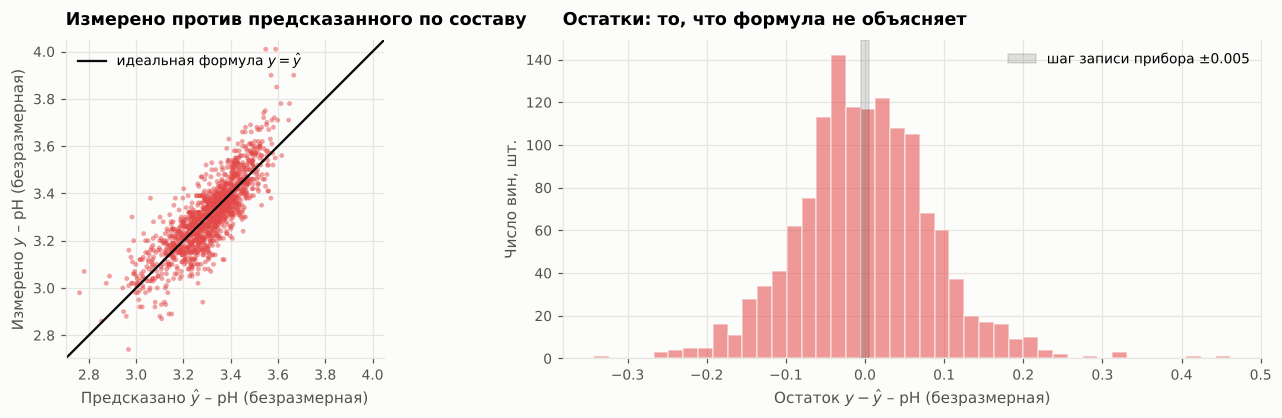

<small>**Рис. 9.** pH: значения, предсказанные линейной формулой по составу, против измеренных (слева) и остатки формулы в сравнении с шагом прибора (справа).</small>

In [13]:
#@title Попытка вычислить pH формулой по остальным 10 показателям
if not all(_n in globals() for _n in ('wine',)):
    class NeedPreviousCells(Exception):
        def _render_traceback_(self):
            return ["⚠ Эта ячейка использует результаты ячеек выше, а они ещё не выполнены.",
                    "  Colab: «Среда выполнения → Выполнить предшествующие» (Ctrl+F8) или «Выполнить все» (Ctrl+F9).",
                    "  Jupyter: «Run → Run All Above Selected Cell» или «Run All Cells»."]
    raise NeedPreviousCells()
FEATURES = [c for c in wine.columns if c != "quality"]
RU = {"fixed acidity": "Фикс. кисл., г/дм³", "volatile acidity": "Летучая кисл., г/дм³",
      "citric acid": "Лимонная к-та, г/дм³", "pH": "pH"}


def randomness_report(target, twin_keys, resolution):
    X = wine[[c for c in FEATURES if c != target]].values
    y = wine[target].values
    rows, preds = [], {}
    for name, quad in [("Линейная МНК, 10 признаков", False), ("Квадратичная МНК, 65 членов", True)]:
        r2, rmse, pred = cv_regression(X, y, quadratic=quad)
        preds[name] = pred
        rows.append((name, r2, 1 - r2, rmse, rmse / resolution))
    lab, unit = VARS[target]["label"], VARS[target]["unit"]
    show(pd.DataFrame(rows, columns=["Модель (5-fold CV)", "R²", "Не объяснено, 1 − R²", f"RMSE ({unit})", "RMSE / шаг прибора"]),
         f"Можно ли вычислить «{lab}» по остальным 10 показателям", fmt="{:.3f}")

    g = wine.groupby(twin_keys)[target].agg(["count", "min", "max"])
    g = g[g["count"] >= 2]
    g["Разброс"] = g["max"] - g["min"]
    twins = g.sort_values("Разброс", ascending=False).reset_index()
    twins.columns = [*[RU[k] for k in twin_keys], "Вин в группе", f"{lab}: min", f"{lab}: max", "Разброс"]
    print(f"Групп «двойников» (совпадают {', '.join(RU[k].split(',')[0] for k in twin_keys)}): {len(g)}, "
          f"из них с разным значением «{lab}»: {(g['Разброс'] > 0).sum()}")
    show(twins.head(5), f"Пять групп «двойников» с наибольшим разбросом «{lab}»", fmt="{:.3g}")
    return y, preds["Линейная МНК, 10 признаков"]


y_ph, pred_ph = randomness_report("pH", ["fixed acidity", "volatile acidity", "citric acid"], resolution=0.01)
randomness_figure(y_ph, pred_ph, "pH", resolution=0.01,
                  caption="pH: значения, предсказанные линейной формулой по составу, против измеренных (слева) и остатки формулы в сравнении с шагом прибора (справа).")

**Вывод.** Даже лучшая формула по 10 остальным показателям объясняет только 70 % разброса pH ($R^2 \approx 0.70$). Мы усложнили её до 65 членов с квадратами и произведениями, стало $0.73$, почти без пользы. Ошибка около $0.086$ ед. pH, это в 8–9 раз больше шага, с которым прибор записывает значения, так что дело не в округлении. Самое наглядное – «двойники»: у вин с одинаковыми фиксированной, летучей и лимонной кислотностью pH отличается до $0.35$. Значит, pH по составу не вычисляется, это случайная величина.

<a id="ktvd-2-3"></a>


### 3.2.3 EDA & Distribution

Статистика,Значение,Ед. изм.
Объём выборки n,1359,шт.
Пропущенные значения,0,шт.
Среднее x̄,3.31,безразмерная
Медиана,3.31,безразмерная
Мода,3.3,безразмерная
Дисперсия s²,0.02404,–
СКО s,0.155,безразмерная
Коэф. вариации s / |x̄|,0.04684,–
Минимум,2.74,безразмерная
Квартиль Q₁,3.21,безразмерная


Распределение,Параметров k,AIC,КС: D,КС: p-value,Вывод (α = 0.05)
Логистическое,2,-1225,0.02546,0.3362,не отвергается
Логнормальное,3,-1213,0.03341,0.09409,не отвергается
Гамма,3,-1213,0.03378,0.08791,не отвергается
Нормальное,2,-1207,0.03968,0.02693,отвергается


Нормальность pH: Шапиро–Уилк W = 0.9927, p = 3.08e-06;  Д'Агостино K² = 35.08, p = 2.41e-08
Логистическое: μ = 3.3078, s = 0.0865  →  σ = sπ/√3 = 0.1569


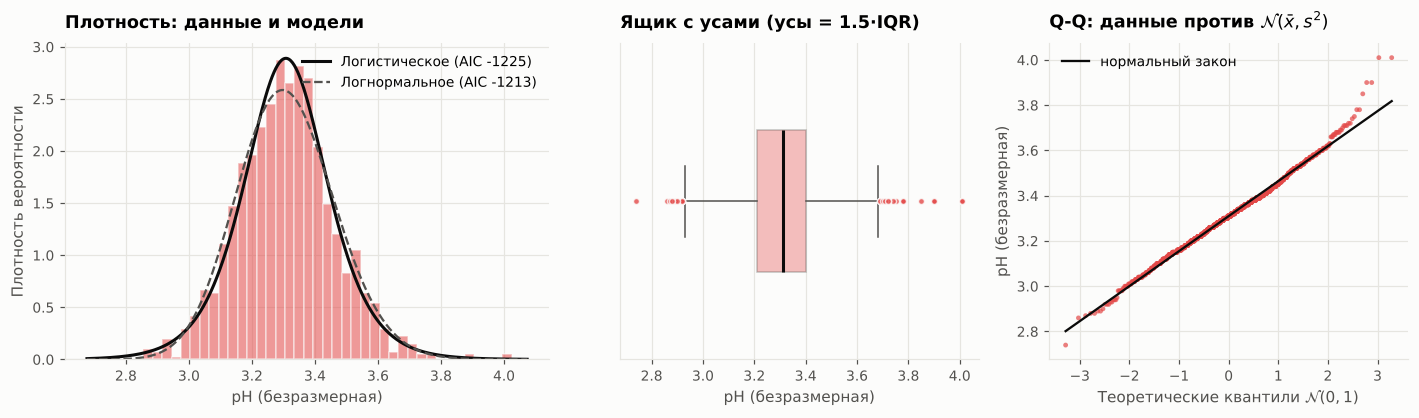

<small>**Рис. 10.** pH: гистограмма с двумя лучшими по AIC моделями, ящик с усами, Q-Q к нормальному закону.</small>

Z-стандартизация: среднее = -0.0000, СКО = 1.0000, γ₁ = 0.2320


In [14]:
#@title Описательные статистики и подбор распределения для pH
if not all(_n in globals() for _n in ('wine',)):
    class NeedPreviousCells(Exception):
        def _render_traceback_(self):
            return ["⚠ Эта ячейка использует результаты ячеек выше, а они ещё не выполнены.",
                    "  Colab: «Среда выполнения → Выполнить предшествующие» (Ctrl+F8) или «Выполнить все» (Ctrl+F9).",
                    "  Jupyter: «Run → Run All Above Selected Cell» или «Run All Cells»."]
    raise NeedPreviousCells()
x_ph = wine["pH"].values
show(describe_rv(x_ph, "pH"), "Описательные статистики pH")
fits_ph = fit_candidates(x_ph)
show(fits_ph.drop(columns=["_params", "_dist"]), "Какое распределение лучше описывает pH", highlight_row=0)
sw, k2 = stats.shapiro(x_ph), stats.normaltest(x_ph)
print(f"Нормальность pH: Шапиро–Уилк W = {sw.statistic:.4f}, p = {sw.pvalue:.2e};  Д'Агостино K² = {k2.statistic:.2f}, p = {k2.pvalue:.2e}")
loc_ph, s_ph = fits_ph.loc[fits_ph["Распределение"] == "Логистическое", "_params"].iloc[0]
print(f"Логистическое: μ = {loc_ph:.4f}, s = {s_ph:.4f}  →  σ = sπ/√3 = {s_ph * np.pi / np.sqrt(3):.4f}")
eda_figure(x_ph, "pH", models_from_fits(fits_ph),
           caption="pH: гистограмма с двумя лучшими по AIC моделями, ящик с усами, Q-Q к нормальному закону.")
z_ph = (x_ph - x_ph.mean()) / x_ph.std(ddof=1)
print(f"Z-стандартизация: среднее = {z_ph.mean():.4f}, СКО = {z_ph.std(ddof=1):.4f}, γ₁ = {pd.Series(z_ph).skew():.4f}")

**Распределение pH.** pH почти симметричен: среднее и медиана совпадают ($3.31$), асимметрия маленькая ($\gamma_1 = 0.23$). Но хвосты у него тяжелее, чем у нормального закона ($\gamma_2 = 0.88$): на Q-Q графике крайние точки уходят от прямой. Шапиро–Уилк нормальность отвергает ($p \approx 3 \cdot 10^{-6}$).

Лучше всего подошло **логистическое распределение**: оно лучшее по AIC, и критерий Колмогорова–Смирнова его не отвергает ($p = 0.34$):

$$
f(x) = \frac{e^{-(x-\mu)/s}}{s\left(1 + e^{-(x-\mu)/s}\right)^2}, \qquad
F(x) = \frac{1}{1 + e^{-(x-\mu)/s}}, \qquad
\sigma^2 = \frac{s^2 \pi^2}{3},
$$

Параметры: $\mu = 3.308$, $s = 0.087$. По форме логистический закон похож на нормальный, но его эксцесс $\gamma_2 = 1.2$ [К2], а это ближе к нашим $0.88$, чем ноль у нормального. Забавно, что для $\lg S$ в [разделе 1.1](#rv01-eda) логистическая модель тоже прошла тест КС, а нормальная нет. Обе величины – логарифмы концентраций, возможно, это не совпадение.

*Оговорка: параметры оценены по тем же данным, поэтому p-value критерия КС здесь завышены (поправка Лиллиефорса). Сравнение моделей по AIC от этого не зависит.*


[↑ к оглавлению](#toc)

<a id="ktvd-3"></a>


## 3.3 Random Variable K2 – фиксированная кислотность

<a id="ktvd-3-1"></a>


### 3.3.1 Description (природа события)

**Событие:** у того же случайно выбранного вина титрованием определяют массовую концентрацию нелетучих кислот и пересчитывают на винную кислоту, г/дм³. Шаг записи $0.1$ г/дм³.

**Почему это случайная величина.** Количество винной и яблочной кислоты в ягоде зависит от того, насколько жарким было лето: в тёплый год яблочная кислота «сгорает» при созревании. Потом кислотность меняется при брожении. Яблочно-молочное брожение превращает двухосновную яблочную кислоту в одноосновную молочную и снижает титруемую кислотность. Винодел может ещё и подкислить или раскислить вино. Ничего из этого в таблице нет, так что по остальным показателям кислотность однозначно не вычисляется. Проверка та же, что для pH.

<a id="ktvd-3-2"></a>


### 3.3.2 Доказательство случайности

Модель (5-fold CV),R²,"Не объяснено, 1 − R²",RMSE (г/дм³),RMSE / шаг прибора
"Линейная МНК, 10 признаков",0.870,0.130,0.627,6.269
"Квадратичная МНК, 65 членов",0.869,0.131,0.629,6.287


Групп «двойников» (совпадают Летучая кисл., Лимонная к-та, pH): 25, из них с разным значением «Фикс. кислотность»: 16


"Летучая кисл., г/дм³","Лимонная к-та, г/дм³",pH,Вин в группе,Фикс. кислотность: min,Фикс. кислотность: max,Разброс
0.67,0.55,3.17,2,8.1,11.2,3.1
0.33,0.32,3.3,2,6,8.2,2.2
0.69,0,3.35,2,7,9,2
0.43,0.36,3.34,2,7,8,1
0.44,0.49,3.23,2,9,10,1


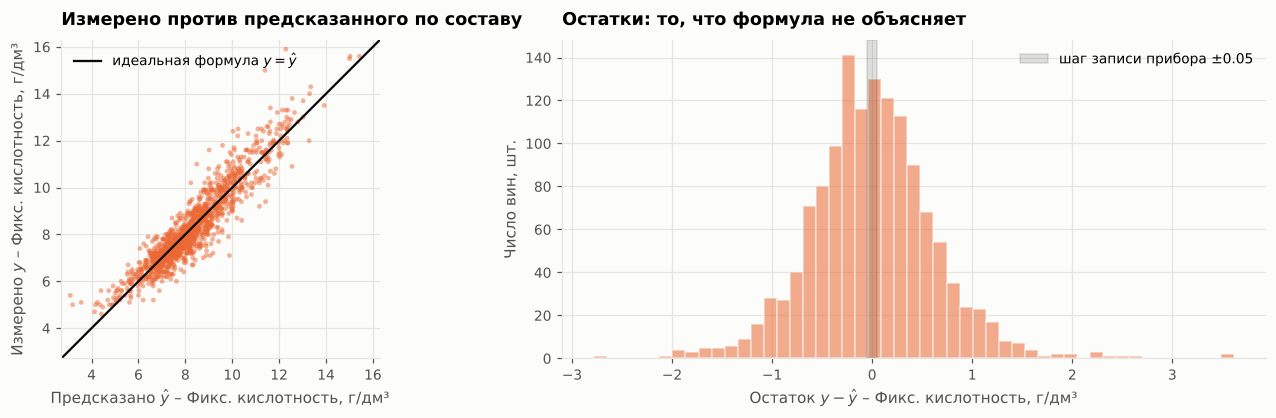

<small>**Рис. 11.** Фиксированная кислотность: предсказание линейной формулой по составу против измерения и остатки формулы.</small>

In [15]:
#@title Попытка вычислить фиксированную кислотность формулой по остальным 10 показателям
if not all(_n in globals() for _n in ('randomness_report',)):
    class NeedPreviousCells(Exception):
        def _render_traceback_(self):
            return ["⚠ Эта ячейка использует результаты ячеек выше, а они ещё не выполнены.",
                    "  Colab: «Среда выполнения → Выполнить предшествующие» (Ctrl+F8) или «Выполнить все» (Ctrl+F9).",
                    "  Jupyter: «Run → Run All Above Selected Cell» или «Run All Cells»."]
    raise NeedPreviousCells()
y_fa, pred_fa = randomness_report("fixed acidity", ["volatile acidity", "citric acid", "pH"], resolution=0.1)
randomness_figure(y_fa, pred_fa, "fixed acidity", resolution=0.1,
                  caption="Фиксированная кислотность: предсказание линейной формулой по составу против измерения и остатки формулы.")

**Вывод.** Кислотность угадывается по составу лучше, чем pH ($R^2 = 0.87$): она сильно связана с плотностью и лимонной кислотой. Но ошибка всё равно около $0.63$ г/дм³, в 6 раз больше шага записи. Квадратичная модель ничего не добавила ($0.869$ против $0.870$), значит, мы упёрлись в шум, а не в простоту формулы. У вин с одинаковыми летучей кислотностью, лимонной кислотой и pH фиксированная кислотность различается до $3.1$ г/дм³. Это тоже случайная величина.

<a id="ktvd-3-3"></a>


### 3.3.3 EDA & Distribution

Статистика,Значение,Ед. изм.
Объём выборки n,1359,шт.
Пропущенные значения,0,шт.
Среднее x̄,8.311,г/дм³
Медиана,7.9,г/дм³
Мода,7.2,г/дм³
Дисперсия s²,3.017,(г/дм³)²
СКО s,1.737,г/дм³
Коэф. вариации s / |x̄|,0.209,–
Минимум,4.6,г/дм³
Квартиль Q₁,7.1,г/дм³


Распределение,Параметров k,AIC,КС: D,КС: p-value,Вывод (α = 0.05)
Логнормальное,3,5161,0.05183,0.0013,отвергается
Гамма,3,5170,0.05825,0.000189,отвергается
Логистическое,2,5322,0.07474,4.771e-07,отвергается
Нормальное,2,5360,0.1081,2.697e-14,отвергается


Логнормальное (3 параметра): σ = 0.3039, сдвиг x₀ = 2.7535, e^μ = 5.3054


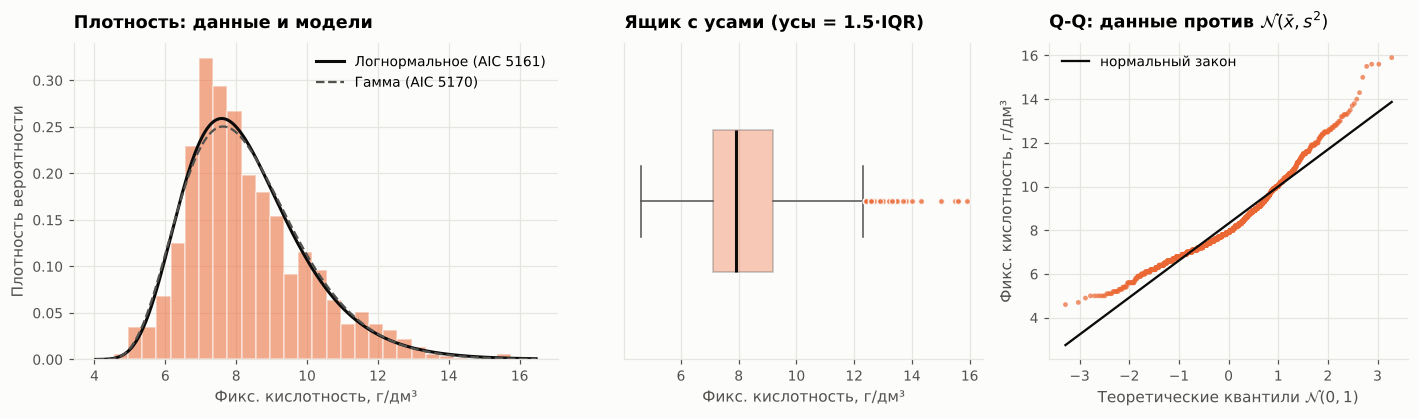

<small>**Рис. 12.** Фиксированная кислотность: гистограмма с двумя лучшими по AIC моделями, ящик с усами, Q-Q к нормальному закону.</small>

Преобразование,γ₁,γ₂,Шапиро–Уилк p
Z-стандартизация z = (x − x̄) / s,0.941,1.05,9.9e-22
"Логарифм ln x, затем z",0.349,0.0792,1.73e-09
"Бокс–Кокс, λ = -0.59",0.000218,0.0577,2.57e-05


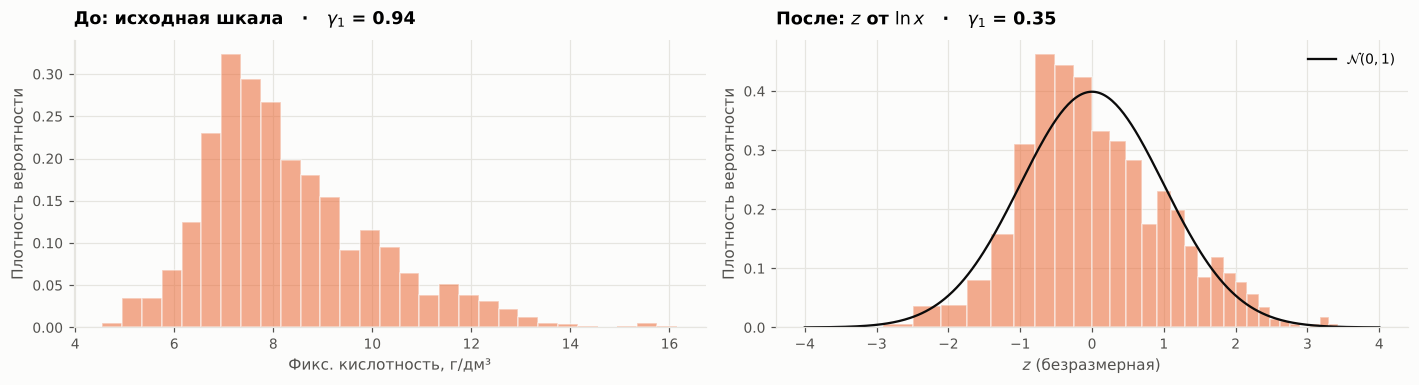

<small>**Рис. 13.** Нормализация кислотности: исходная шкала и z-оценка логарифма в сравнении со стандартным нормальным законом.</small>

In [16]:
#@title Описательные статистики, подбор распределения и нормализация фиксированной кислотности
if not all(_n in globals() for _n in ('wine',)):
    class NeedPreviousCells(Exception):
        def _render_traceback_(self):
            return ["⚠ Эта ячейка использует результаты ячеек выше, а они ещё не выполнены.",
                    "  Colab: «Среда выполнения → Выполнить предшествующие» (Ctrl+F8) или «Выполнить все» (Ctrl+F9).",
                    "  Jupyter: «Run → Run All Above Selected Cell» или «Run All Cells»."]
    raise NeedPreviousCells()
x_fa = wine["fixed acidity"].values
show(describe_rv(x_fa, "fixed acidity"), "Описательные статистики фиксированной кислотности")
fits_fa = fit_candidates(x_fa)
show(fits_fa.drop(columns=["_params", "_dist"]), "Какое распределение лучше описывает кислотность", highlight_row=0)
sigma_ln, loc_ln, scale_ln = fits_fa.loc[fits_fa["Распределение"] == "Логнормальное", "_params"].iloc[0]
print(f"Логнормальное (3 параметра): σ = {sigma_ln:.4f}, сдвиг x₀ = {loc_ln:.4f}, e^μ = {scale_ln:.4f}")
eda_figure(x_fa, "fixed acidity", models_from_fits(fits_fa),
           caption="Фиксированная кислотность: гистограмма с двумя лучшими по AIC моделями, ящик с усами, Q-Q к нормальному закону.")

ln_fa = np.log(x_fa)
bc_fa, lam = stats.boxcox(x_fa)
z_fa = (x_fa - x_fa.mean()) / x_fa.std(ddof=1)
show(pd.DataFrame([
    ("Z-стандартизация z = (x − x̄) / s", pd.Series(z_fa).skew(), pd.Series(z_fa).kurtosis(), stats.shapiro(z_fa).pvalue),
    ("Логарифм ln x, затем z", pd.Series(ln_fa).skew(), pd.Series(ln_fa).kurtosis(), stats.shapiro(ln_fa).pvalue),
    (f"Бокс–Кокс, λ = {lam:.2f}", pd.Series(bc_fa).skew(), pd.Series(bc_fa).kurtosis(), stats.shapiro(bc_fa).pvalue),
], columns=["Преобразование", "γ₁", "γ₂", "Шапиро–Уилк p"]), "Нормализация кислотности", fmt="{:.3g}")

fig, ax = plt.subplots(1, 2, figsize=(13, 3.6))
edges = step_bins(x_fa, VARS["fixed acidity"]["step"])
to_z = lambda v: (np.log(v) - ln_fa.mean()) / ln_fa.std(ddof=1)   # то же преобразование для границ бинов
for a_, d_, b_, t_, xl_ in [(ax[0], x_fa, edges, "До: исходная шкала", VARS["fixed acidity"]["axis"]),
                            (ax[1], to_z(x_fa), to_z(edges), "После: $z$ от $\\ln x$", "$z$ (безразмерная)")]:
    a_.hist(d_, bins=b_, density=True, color=VARS["fixed acidity"]["color"], alpha=0.55, edgecolor=STYLE["surface"], linewidth=1)
    a_.set_title(f"{t_}   ·   $\\gamma_1$ = {pd.Series(d_).skew():.2f}")
    a_.set_xlabel(xl_); a_.set_ylabel("Плотность вероятности")
g = np.linspace(-4, 4, 300)
ax[1].plot(g, stats.norm.pdf(g), color=STYLE["ink"], linewidth=1.5, label="$\\mathcal{N}(0, 1)$")
ax[1].legend(loc="upper right")
fig.tight_layout(); plt.show()
fig_caption("Нормализация кислотности: исходная шкала и z-оценка логарифма в сравнении со стандартным нормальным законом.")

**Распределение кислотности.** У большинства вин кислотность от 7 до 9 г/дм³ ($Q_1 = 7.1$, $Q_3 = 9.2$). Справа длинный хвост, поэтому среднее $8.31$ больше медианы $7.9$, а $\gamma_1 = 0.94$. Кислотность складывается из нескольких кислот, и каждая зависит от погоды, сорта и брожения. Такие эффекты скорее перемножаются, чем складываются, а произведение многих случайных множителей по ЦПТ близко к **логнормальному** закону (его логарифм нормален, см. схему Leemis & McQueston [К2]):

$$
X = x_0 + e^{Y}, \quad Y \sim \mathcal{N}(\mu, \sigma^2) \quad\Longrightarrow\quad
f(x) = \frac{1}{(x - x_0)\,\sigma\sqrt{2\pi}} \exp\!\left(-\frac{\left(\ln(x - x_0) - \mu\right)^2}{2\sigma^2}\right), \quad x > x_0 .
$$

По AIC логнормальная модель лучшая из четырёх, но тест КС её всё-таки отвергает ($p = 0.001$). Даже после логарифма остаётся асимметрия $\gamma_1 = 0.35$, то есть хвост тяжелее логнормального. Полностью асимметрию убирает преобразование Бокса–Кокса с $\lambda \approx -0.6$, оно «сильнее» логарифма ($\lambda = 0$).

**Нормализация.** Обычная $z$-стандартизация только сдвигает и растягивает шкалу, форма не меняется ($\gamma_1$ остаётся $0.94$). Поэтому сначала логарифмируем, потом стандартизируем. Для сравнения с pH, который сам логарифм, это удобная шкала.


[↑ к оглавлению](#toc)

<a id="ktvd-4"></a>


## 3.4 Зависимость pH и фиксированной кислотности

Обе величины описывают кислотность одного и того же вина, поэтому зависимость ожидаема. Проверяем

$$
H_0:\ \text{pH и фиксированная кислотность независимы}, \qquad H_1:\ \text{зависимы},
$$

четырьмя критериями: линейная связь (Пирсон), монотонная связь (Спирмен, Кендалл) и связь любой формы ($\chi^2$ по таблице сопряжённости квартилей).

Нулевая гипотеза H₀,Критерий,Статистика,p-value,Решение (α = 0.05)
pH и кислотность независимы,Пирсон r (кислотность в исходной шкале),-0.6867,3.666e-190,H₀ отвергается
pH и кислотность независимы,Пирсон r (кислотность в лог. шкале),-0.7101,4.833e-209,H₀ отвергается
pH и кислотность независимы,Спирмен ρₛ,-0.7086,1.049e-207,H₀ отвергается
pH и кислотность независимы,Кендалл τ,-0.5295,4.093e-181,H₀ отвергается
pH и кислотность независимы,"χ² сопряжённости 4×4, df = 9",705.4,4.817e-146,H₀ отвергается


Сила связи по таблице сопряжённости: V Крамера = 0.416
Регрессия: pH = 4.464 − 0.550·ln(FA)  →  при удвоении кислотности pH меняется на -0.382, на декаду (×10) – на -1.27


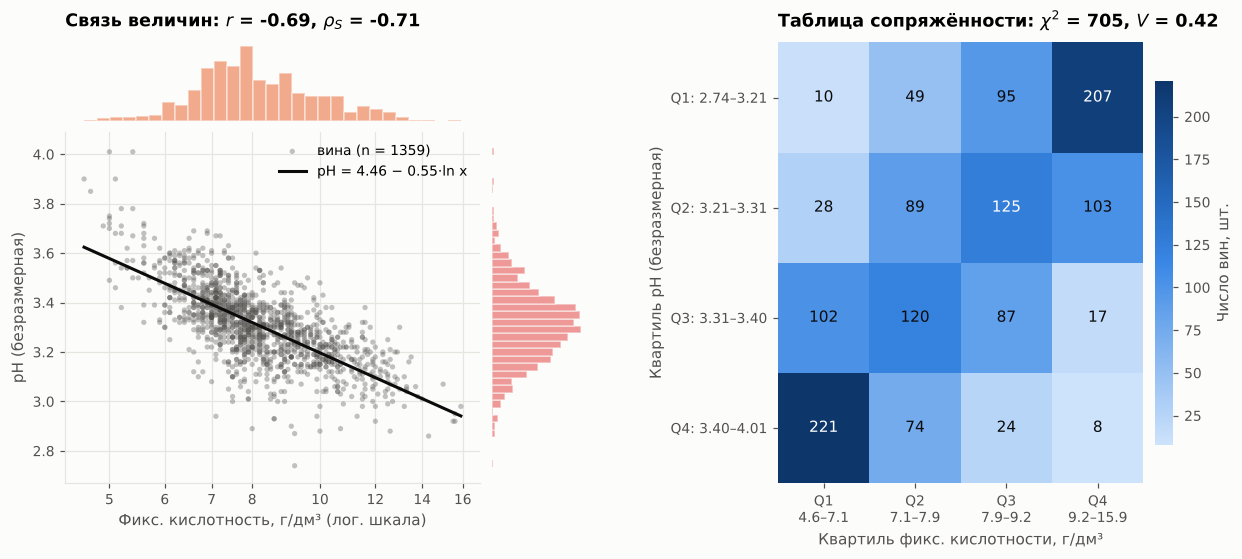

<small>**Рис. 14.** Связь pH и фиксированной кислотности: диаграмма рассеяния в логарифмической шкале с маргинальными распределениями (слева) и таблица сопряжённости по квартилям (справа).</small>

In [17]:
#@title Критерии независимости и графики связи
if not all(_n in globals() for _n in ('wine',)):
    class NeedPreviousCells(Exception):
        def _render_traceback_(self):
            return ["⚠ Эта ячейка использует результаты ячеек выше, а они ещё не выполнены.",
                    "  Colab: «Среда выполнения → Выполнить предшествующие» (Ctrl+F8) или «Выполнить все» (Ctrl+F9).",
                    "  Jupyter: «Run → Run All Above Selected Cell» или «Run All Cells»."]
    raise NeedPreviousCells()
x, y = wine["fixed acidity"].values, wine["pH"].values
pr, pr_ln = stats.pearsonr(x, y), stats.pearsonr(np.log(x), y)
sp, kt = stats.spearmanr(x, y), stats.kendalltau(x, y)
table = pd.crosstab(pd.qcut(y, 4, labels=["Q1", "Q2", "Q3", "Q4"]), pd.qcut(x, 4, labels=["Q1", "Q2", "Q3", "Q4"]))
chi = stats.chi2_contingency(table)
cramer_v = np.sqrt(chi.statistic / (table.values.sum() * (min(table.shape) - 1)))
hyp_table([
    ("pH и кислотность независимы", "Пирсон r (кислотность в исходной шкале)", pr.statistic, pr.pvalue),
    ("pH и кислотность независимы", "Пирсон r (кислотность в лог. шкале)", pr_ln.statistic, pr_ln.pvalue),
    ("pH и кислотность независимы", "Спирмен ρₛ", sp.statistic, sp.pvalue),
    ("pH и кислотность независимы", "Кендалл τ", kt.statistic, kt.pvalue),
    ("pH и кислотность независимы", f"χ² сопряжённости 4×4, df = {chi.dof}", chi.statistic, chi.pvalue),
], "Проверка независимости pH и фиксированной кислотности")
print(f"Сила связи по таблице сопряжённости: V Крамера = {cramer_v:.3f}")
b, a0 = np.polyfit(np.log(x), y, 1)
print(f"Регрессия: pH = {a0:.3f} − {abs(b):.3f}·ln(FA)  →  при удвоении кислотности pH меняется на {b * np.log(2):+.3f}, "
      f"на декаду (×10) – на {b * np.log(10):+.2f}")

fig = plt.figure(figsize=(13, 5.2))
outer = fig.add_gridspec(1, 2, width_ratios=[5, 3.8], wspace=0.42)
gs = outer[0].subgridspec(2, 2, width_ratios=[4, 0.9], height_ratios=[0.9, 4], wspace=0.05, hspace=0.05)
ax = fig.add_subplot(gs[1, 0]); ax_top = fig.add_subplot(gs[0, 0], sharex=ax); ax_right = fig.add_subplot(gs[1, 1], sharey=ax)
ax.scatter(x, y, s=12, color=STYLE["ink2"], alpha=0.35, edgecolor="none", label=f"вина (n = {len(x)})")
gx = np.geomspace(x.min(), x.max(), 200)
ax.plot(gx, a0 + b * np.log(gx), color=STYLE["ink"], linewidth=2, label=f"pH = {a0:.2f} − {abs(b):.2f}·ln x")
ax.set_xscale("log")
ax.xaxis.set_major_locator(FixedLocator([5, 6, 7, 8, 10, 12, 14, 16])); ax.xaxis.set_minor_locator(NullLocator())
ax.xaxis.set_major_formatter(FuncFormatter(lambda v, _: f"{v:g}"))
ax.set_xlabel(VARS["fixed acidity"]["axis"] + " (лог. шкала)"); ax.set_ylabel(VARS["pH"]["axis"])
ax.legend(loc="upper right")
ax_top.hist(x, bins=np.geomspace(x.min(), x.max(), 30), color=VARS["fixed acidity"]["color"], alpha=0.55, edgecolor=STYLE["surface"], linewidth=1)
ax_right.hist(y, bins=step_bins(y, 0.01), orientation="horizontal", color=VARS["pH"]["color"], alpha=0.55,
              edgecolor=STYLE["surface"], linewidth=1)
for a_ in (ax_top, ax_right):
    a_.tick_params(labelbottom=False, labelleft=False, bottom=False, left=False); a_.grid(False)
    for s_ in a_.spines.values():
        s_.set_visible(False)
ax_top.set_title(f"Связь величин: $r$ = {pr.statistic:.2f}, $\\rho_S$ = {sp.statistic:.2f}")

axh = fig.add_subplot(outer[1])
cmap = mpl.colors.LinearSegmentedColormap.from_list("seq", STYLE["seq"][1:])
im = axh.imshow(table.values, cmap=cmap, aspect="auto")
for (i, j), v in np.ndenumerate(table.values):
    axh.text(j, i, f"{v}", ha="center", va="center", fontsize=10, color="white" if v > table.values.max() * 0.55 else STYLE["ink"])
qx, qy = np.quantile(x, [0, .25, .5, .75, 1]), np.quantile(y, [0, .25, .5, .75, 1])
axh.set_xticks(range(4), [f"Q{i + 1}\n{qx[i]:.1f}–{qx[i + 1]:.1f}" for i in range(4)])
axh.set_yticks(range(4), [f"Q{i + 1}: {qy[i]:.2f}–{qy[i + 1]:.2f}" for i in range(4)])
axh.grid(False); axh.set_xlabel("Квартиль фикс. кислотности, г/дм³"); axh.set_ylabel("Квартиль pH (безразмерная)")
axh.set_title(f"Таблица сопряжённости: $\\chi^2$ = {chi.statistic:.0f}, $V$ = {cramer_v:.2f}")
for s_ in axh.spines.values():
    s_.set_visible(False)
cb = fig.colorbar(im, ax=axh, fraction=0.046, pad=0.03); cb.set_label("Число вин, шт.", color=STYLE["ink2"]); cb.outline.set_visible(False)
plt.show()
fig_caption("Связь pH и фиксированной кислотности: диаграмма рассеяния в логарифмической шкале с маргинальными распределениями (слева) и таблица сопряжённости по квартилям (справа).")

**Вывод.** Независимость отвергают все критерии, $p$-value меньше $10^{-140}$. Связь обратная и сильная ($r = -0.69$, $\rho_S = -0.71$, $V = 0.42$): чем больше в вине кислот, тем ниже pH, как и должно быть. В таблице сопряжённости это хорошо видно: из 361 наименее кислого вина 221 попало в верхнюю четверть по pH, а из 335 самых кислых 207 – в нижнюю. Если бы величины были независимы, в каждой клетке было бы 80–96 вин.

**Почему связь линейна в логарифмах.** pH – это логарифм, поэтому с $\ln x$ кислотность коррелирует чуть сильнее ($r = -0.71$), чем с $x$ ($-0.69$). По наклону регрессии при росте кислотности в 10 раз pH падает примерно на $1.27$. Мы сравнили это с двумя простыми моделями. Если бы вино было просто раствором слабой кислоты, по формуле $[\mathrm{H^+}] \approx \sqrt{K_a C}$ наклон был бы $-0.5$ на декаду. Но вино – буфер: часть кислот нейтрализована калием [К3], и тогда работает уравнение Хендерсона–Хассельбаха:

$$
\mathrm{pH} = \mathrm{p}K_a + \lg\frac{[\mathrm{A^-}]}{[\mathrm{HA}]} \approx \mathrm{p}K_a + \lg\frac{[\mathrm{K^+}]}{C - [\mathrm{K^+}]}
\quad\Longrightarrow\quad
\frac{d\,\mathrm{pH}}{d \lg C} = -\frac{C}{C - [\mathrm{K^+}]} < -1 .
$$

Наш наклон $-1.27$ подходит под буферную модель, а не под модель «чистой кислоты». Калий в датасете не измеряли, и это объясняет, почему связь не строгая ($r^2 \approx 0.5$): при одной и той же кислотности pH зависит ещё от того, сколько калия было в винограде.


[↑ к оглавлению](#toc)

<a id="ktvd-5"></a>


## 3.5 Интерактивный генератор

Генератор из [спринта 2](#gen01-code) (`InfoChemRandomGenerator`) расширен третьим методом – эмпирическим квантильным преобразованием $X = \hat{F}_n^{-1}(U)$: случайное $U \sim \mathcal{U}(0, 1)$ превращается в квантиль самих данных (линейная интерполяция между порядковыми статистиками $x_{(i)}$ в точках $p_i = (i - \tfrac12)/n$). Этот метод добавлен из-за находки в [2.1.5](#gen01-resume): параметрические законы симметричны и не воспроизводят асимметрию $\lg S$.

<a id="ktvd-5-1"></a>


### 3.5.1 Три метода на трёх величинах

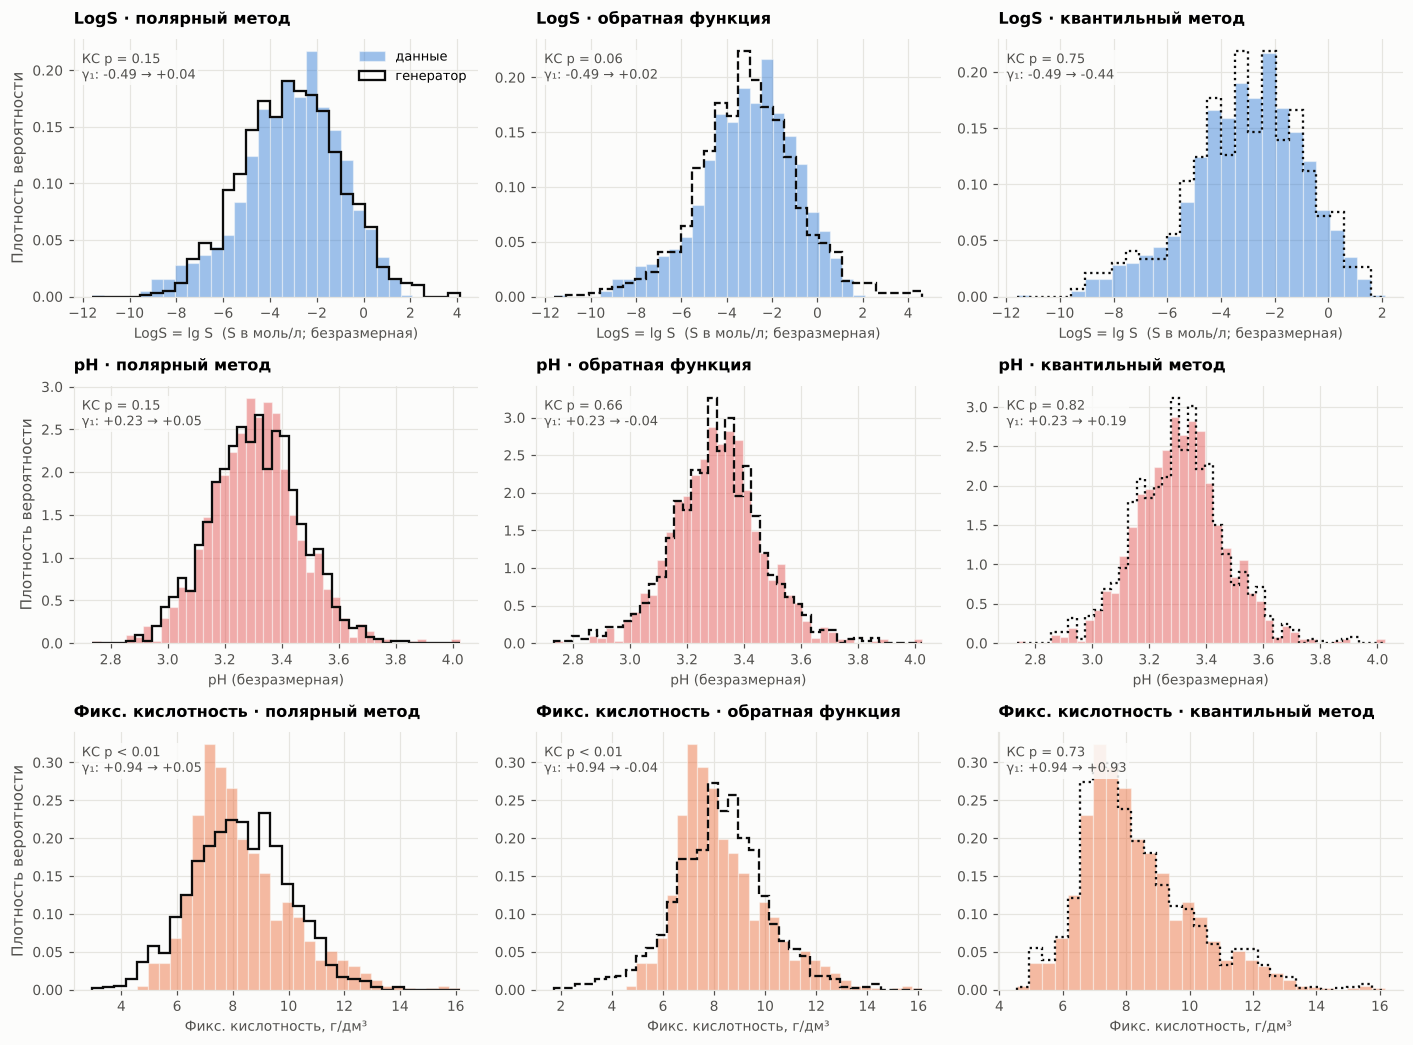

<small>**Рис. 15.** Данные (цвет величины) и выборки генераторов того же объёма (графитовая линия), seed = 2026. В углу каждой панели – p-value двухвыборочного критерия КС и асимметрия «данные → генератор».</small>

Величина,Метод,КС p-value,Данные и генератор (α = 0.05),"Ошибка x̄, %","Ошибка s, %",γ₁ данных,γ₁ генератора,min генератора,max генератора
LogS,Полярный метод Марсальи,0.151,не различаются,0.823,1.23,-0.492,0.0446,-9.11,3.8
LogS,Обратная функция (логистич.),0.0593,не различаются,1.27,3.7,-0.492,0.0211,-10.8,4.37
LogS,Квантильное преобразование,0.755,не различаются,1.57,3.43,-0.492,-0.442,-9.54,1.49
pH,Полярный метод Марсальи,0.154,не различаются,0.0402,1.61,0.232,0.0468,2.86,3.82
pH,Обратная функция (логистич.),0.663,не различаются,0.145,3.62,0.232,-0.0364,2.74,3.86
pH,Квантильное преобразование,0.818,не различаются,0.136,3.38,0.232,0.192,2.86,3.93
Фикс. кислотность,Полярный метод Марсальи,8.68e-07,различаются,0.179,1.61,0.94,0.0468,3.29,14
Фикс. кислотность,Обратная функция (логистич.),6.41e-08,различаются,0.648,3.62,0.94,-0.0364,1.91,14.5
Фикс. кислотность,Квантильное преобразование,0.727,не различаются,0.388,2.77,0.94,0.932,4.74,15.6


In [18]:
#@title Сравнение трёх методов генерации на LogS, pH и фикс. кислотности
if not all(_n in globals() for _n in ('InfoChemRandomGenerator', 'data', 'wine')):
    class NeedPreviousCells(Exception):
        def _render_traceback_(self):
            return ["⚠ Эта ячейка использует результаты ячеек выше, а они ещё не выполнены.",
                    "  Colab: «Среда выполнения → Выполнить предшествующие» (Ctrl+F8) или «Выполнить все» (Ctrl+F9).",
                    "  Jupyter: «Run → Run All Above Selected Cell» или «Run All Cells»."]
    raise NeedPreviousCells()
class GeneratorKTvD(InfoChemRandomGenerator):
    """Генератор спринта 2 + метод 3: эмпирическое квантильное преобразование (тот же базовый MT19937)."""

    def empirical_quantile(self, n: int, data: np.ndarray) -> np.ndarray:
        xs = np.sort(np.asarray(data, dtype=float))
        p = (np.arange(1, xs.size + 1) - 0.5) / xs.size
        return np.interp(self.rng.random(n), p, xs)

    def sample(self, method: str, n: int, data: np.ndarray) -> np.ndarray:
        mu, sigma = float(np.mean(data)), float(np.std(data, ddof=1))
        if method == "polar":
            return self.generate_polar_marsaglia(n, mu, sigma)
        if method == "inverse":
            return self.generate_inverse_logistic(n, mu, sigma)
        return self.empirical_quantile(n, data)


SOURCES = {"LogS": data["LogS"].values, "pH": wine["pH"].values, "fixed acidity": wine["fixed acidity"].values}
rows = []
fig, axes = plt.subplots(3, 3, figsize=(13, 9.6))
for i, key in enumerate(SOURCES):
    real = SOURCES[key]
    for j, method in enumerate(["polar", "inverse", "quantile"]):
        synth = GeneratorKTvD(seed=2026).sample(method, len(real), real)
        ks = generator_panel(axes[i, j], real, synth, key, method, legend=(i == 0 and j == 0))
        axes[i, j].set_title(f"{VARS[key]['label']} · {METHOD_SHORT[method]}", fontsize=10.5)
        if j == 0:
            axes[i, j].set_ylabel("Плотность вероятности")
        axes[i, j].set_xlabel(VARS[key]["axis"], fontsize=9)
        rows.append((VARS[key]["label"], METHOD_NAME[method], ks.pvalue,
                     "не различаются" if ks.pvalue > ALPHA else "различаются",
                     abs(synth.mean() - real.mean()) / abs(real.mean()) * 100,
                     abs(synth.std(ddof=1) - real.std(ddof=1)) / real.std(ddof=1) * 100,
                     stats.skew(real), stats.skew(synth), synth.min(), synth.max()))
fig.tight_layout(); plt.show()
fig_caption("Данные (цвет величины) и выборки генераторов того же объёма (графитовая линия), seed = 2026. В углу каждой панели – p-value двухвыборочного критерия КС и асимметрия «данные → генератор».")

summary = pd.DataFrame(rows, columns=["Величина", "Метод", "КС p-value", "Данные и генератор (α = 0.05)",
                                      "Ошибка x̄, %", "Ошибка s, %", "γ₁ данных", "γ₁ генератора", "min генератора", "max генератора"])
show(summary, "Итоговые метрики: 3 метода × 3 величины", fmt="{:.3g}")

**Что видно.** На $\lg S$ и pH тест КС не отличает от данных ни один из трёх методов. Но по таблице видно, что симметричные законы форму всё же теряют: асимметрию $\lg S$ ($-0.49$) сохраняет только квантильный метод ($-0.44$), у остальных она около нуля. На фиксированной кислотности с её длинным правым хвостом ($\gamma_1 = 0.94$) оба параметрических генератора тест КС проваливают, а квантильный проходит. У квантильного метода свой минус: он не выходит за пределы наблюдённых значений, то есть новых рекордов не придумает.

<a id="ktvd-5-2"></a>


### 3.5.2 Интерактивная версия в ноутбуке

Когда все ячейки выше выполнены, запустите ячейку ниже: появятся выбор величины и метода, ползунки объёма выборки и числа бинов, поле seed. Графики и метрики пересчитываются при каждом изменении. Нужен пакет `ipywidgets`: в Colab он уже есть, локально – `pip install ipywidgets`.

In [ ]:
#@title Интерактивный генератор (ipywidgets): запустите ячейку
if not all(_n in globals() for _n in ('SOURCES', 'GeneratorKTvD')):
    class NeedPreviousCells(Exception):
        def _render_traceback_(self):
            return ["⚠ Эта ячейка использует результаты ячеек выше, а они ещё не выполнены.",
                    "  Colab: «Среда выполнения → Выполнить предшествующие» (Ctrl+F8) или «Выполнить все» (Ctrl+F9).",
                    "  Jupyter: «Run → Run All Above Selected Cell» или «Run All Cells»."]
    raise NeedPreviousCells()
def interactive_generator(key="LogS", method="polar", n=1000, seed=2026, nbins=35):
    real = SOURCES[key]
    synth = GeneratorKTvD(seed=int(seed)).sample(method, int(n), real)
    lo, hi = min(real.min(), synth.min()), max(real.max(), synth.max())
    bins = np.linspace(lo, hi, int(nbins) + 1)
    fig, ax = plt.subplots(1, 3, figsize=(13, 3.8))
    ks = generator_panel(ax[0], real, synth, key, method, bins=bins)
    ax[0].set_title("Плотность"); ax[0].set_xlabel(VARS[key]["axis"]); ax[0].set_ylabel("Плотность вероятности")
    for s_, col_, ls_, lab_ in [(real, VARS[key]["color"], "-", "данные"), (synth, STYLE["ink"], METHOD_LS[method], "генератор")]:
        ss = np.sort(s_)
        ax[1].step(ss, np.arange(1, ss.size + 1) / ss.size, where="post", color=col_, linestyle=ls_, linewidth=1.8, label=lab_)
    ax[1].set_title("Функции распределения"); ax[1].set_xlabel(VARS[key]["axis"]); ax[1].set_ylabel("$\\hat{F}(x)$"); ax[1].legend(loc="upper left")
    p = np.linspace(0.005, 0.995, 120)
    qr, qs = np.quantile(real, p), np.quantile(synth, p)
    ax[2].scatter(qr, qs, s=12, color=VARS[key]["color"], edgecolor="none")
    ax[2].plot([qr.min(), qr.max()], [qr.min(), qr.max()], color=STYLE["ink2"], linestyle="--", linewidth=1.2, label="y = x")
    ax[2].set_title("Q-Q: генератор против данных"); ax[2].set_xlabel("Квантили данных"); ax[2].set_ylabel("Квантили генератора")
    ax[2].legend(loc="upper left")
    fig.tight_layout(); plt.show()
    print(f"{METHOD_NAME[method]} · {VARS[key]['label']}:  КС p = {ks.pvalue:.3f}  |  ошибка x̄ = "
          f"{abs(synth.mean() - real.mean()) / abs(real.mean()):.2%}  |  ошибка s = {abs(synth.std(ddof=1) - real.std(ddof=1)) / real.std(ddof=1):.2%}"
          f"  |  γ₁: данные {stats.skew(real):+.2f}, генератор {stats.skew(synth):+.2f}")


try:
    import ipywidgets as W
except ImportError:
    W = None

if W is None:
    print("Для интерактивной версии нужен ipywidgets: %pip install ipywidgets (в Colab он уже установлен).")
    interactive_generator()
else:
    key_w = W.Dropdown(options=[("LogS – растворимость (ESOL)", "LogS"), ("pH – вино", "pH"), ("Фикс. кислотность – вино", "fixed acidity")],
                       value="LogS", description="Величина", layout=W.Layout(width="360px"))
    method_w = W.ToggleButtons(options=[("Полярный", "polar"), ("Обратная функция", "inverse"), ("Квантильный", "quantile")],
                               value="polar", description="Метод")
    n_w = W.IntSlider(value=1000, min=100, max=20000, step=100, description="n", continuous_update=False)
    seed_w = W.IntText(value=2026, description="seed", layout=W.Layout(width="200px"))
    bins_w = W.IntSlider(value=35, min=10, max=80, description="Бины", continuous_update=False)
    out = W.interactive_output(interactive_generator, dict(key=key_w, method=method_w, n=n_w, seed=seed_w, nbins=bins_w))
    display(W.VBox([W.HBox([key_w, seed_w]), method_w, W.HBox([n_w, bins_w]), out]))

<a id="ktvd-5-3"></a>


### 3.5.3 Приложение на marimo

То же самое в виде отдельного реактивного приложения – файл `ktvd_generator_marimo.py`. В marimo каждая ячейка – функция от своих входов: двигаешь ползунок, и пересчитываются только зависящие от него ячейки. В режиме `marimo run` код скрыт, видна только панель управления. Сверх виджетов выше там есть ручная настройка $\mu$ и $\sigma$, доля принятых точек полярного метода (теория $\pi/4 \approx 78.5\,\%$) и обозреватель связей между любыми двумя показателями вина.

```bash
pip install marimo pandas numpy scipy matplotlib
marimo run ktvd_generator_marimo.py    # режим приложения, код скрыт
marimo edit ktvd_generator_marimo.py   # режим редактирования
```


[↑ к оглавлению](#toc)

<a id="ktvd-6"></a>


## 3.6 Lab resume КТвД

<a id="ktvd-6-1"></a>


### 3.6.1 Выводы

1. **Данные.** В Wine Quality (red) из 1599 строк 240 оказались дубликатами, работали с 1359 винами. Строки в файле идут не в случайном порядке (критерий серий, $p < 0.001$), поэтому подвыборки берём только после перемешивания.
2. **Случайность.** Ни pH, ни кислотность нельзя вычислить по остальным показателям. Лучшая формула не объясняет 30 % и 13 % разброса, а у вин-«двойников» значения различаются до $0.35$ ед. pH и $3.1$ г/дм³.
3. **pH** почти симметричен ($\gamma_1 = 0.23$), но с тяжёлыми хвостами ($\gamma_2 = 0.88$). Нормальный закон не подошёл, логистический $\mathrm{Logistic}(3.308,\ 0.087)$ подошёл.
4. **Кислотность** скошена вправо ($\gamma_1 = 0.94$) и ближе всего к логнормальной, хотя и не идеально. Чтобы привести её к нормальной, нужен логарифм или Бокс–Кокс.
5. **Зависимость.** Величины зависимы, и сильно ($\rho_S = -0.71$): чем кислее вино, тем ниже pH. Наклон ($-1.27$ на декаду) подходит под буферную формулу Хендерсона–Хассельбаха, а не под модель простой кислоты.
6. **Генератор.** Мы сравнили три метода на трёх величинах. Симметричные законы проходят тест КС на $\lg S$ и pH, но теряют асимметрию, а квантильный метод сохраняет форму везде. Генератор можно крутить прямо в ноутбуке (ipywidgets) и в отдельном приложении на marimo.

<a id="ktvd-6-2"></a>


### 3.6.2 cat_mark_table

| cat_id | notebook_link | coeff | comment |
|--------|---------------|-------|---------|
| `KTVD_STRUCT` | [Оглавление](#toc) |  | Сквозная нумерация разделов, таблиц и рисунков; оглавление, якорные ссылки, переходы «↑ к оглавлению» |
| `KTVD_CODE_HIDDEN` | [3.0.1 Чек-лист](#ktvd-0-1) |  | Весь код скрыт (`source_hidden` + Colab-формы) |
| `KTVD_PLOTS` | [Обозначения и цвета](#notation) |  | Единая палитра и стиль во всём документе, подписи осей с единицами, бины по шагу прибора |
| `KTVD_LATEX` | [Обозначения](#notation) |  | Формулы в LaTeX, единые обозначения $\gamma_1, \gamma_2, \bar{x}, s$ |
| `KTVD_DATASET` | [3.1 Датасет](#ktvd-1) |  | Отдельный датасет, проверка дубликатов и порядка строк |
| `KTVD_RV_PH` | [3.2 pH](#ktvd-2) |  | Доказательство случайности (регрессия + «двойники»), EDA, подбор распределения |
| `KTVD_RV_FA` | [3.3 Кислотность](#ktvd-3) |  | То же + нормализация (ln, Бокс–Кокс) |
| `KTVD_DEPENDENCE` | [3.4 Зависимость](#ktvd-4) |  | 4 критерия независимости, интерпретация через Хендерсона–Хассельбаха |
| `KTVD_INTERACTIVE` | [3.5 Генератор](#ktvd-5) |  | 3 метода × 3 величины, таблица метрик, интерактивные виджеты |
| `KTVD_MARIMO` | [3.5.3 marimo](#ktvd-5-3) |  | Приложение `ktvd_generator_marimo.py` |

### Литература к блоку КТвД

- **[К1]** Cortez P., Cerdeira A., Almeida F., Matos T., Reis J. Modeling wine preferences by data mining from physicochemical properties // *Decision Support Systems*. – 2009. – Vol. 47, No. 4. – P. 547–553.
- **[К2]** Leemis L. M., McQueston J. T. Univariate Distribution Relationships // *The American Statistician*. – 2008. – Vol. 62, No. 1. – P. 45–53.
- **[К3]** Ribéreau-Gayon P., Glories Y., Maujean A., Dubourdieu D. *Handbook of Enology. Vol. 2: The Chemistry of Wine*. – 2nd ed. – Wiley, 2006. – Ch. 1 (органические кислоты, pH и буферные свойства вина).
- **[К4]** Wald A., Wolfowitz J. On a Test Whether Two Samples are from the Same Population // *Annals of Mathematical Statistics*. – 1940. – Vol. 11, No. 2. – P. 147–162.
- **[К5]** marimo – reactive Python notebooks. – URL: https://docs.marimo.io


[↑ к оглавлению](#toc)